# Project 1: News Classification Across Datasets

## Overview

In this project, you will build models that classify news articles by topic. You will represent each article with TF-IDF features (see Part 4) and train two classifiers introduced in this module: logistic regression and a multilayer perceptron (MLP). Transformers and pretrained language models are outside the scope of this project.

You will investigate whether models trained on one news dataset generalize to unseen in-domain articles, transfer to articles collected from a different source, and adapt when category definitions change. You will also study how regularization and limited target-domain training data affect performance.

Key concepts of this project include:
- construct a reproducible text-classification pipeline without evaluation-data leakage;
- compare a linear classifier with a nonlinear neural-network classifier;
- select hyperparameters using validation data and appropriate evaluation metrics;
- analyze in-domain performance, cross-dataset transfer, and category mismatch; and
- support quantitative results with error analysis and clear explanations.


### Dependencies & Notebook Configurations

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

In [2]:
# for reproducibility
np.random.seed(0)
torch.manual_seed(0)

In [3]:
# Use GPU if available
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
else:
    DEVICE = torch.device("cpu")

USE_CUDA = DEVICE.type  == "cuda"

print(f"DEVICE: {DEVICE}")
print(f"USE_CUDA: {USE_CUDA}")

DEVICE: cuda
USE_CUDA: True


## Data Load & Preprocessing

In [4]:
# Set A
SOURCE_A_TRAIN = pd.read_csv("./dataset/dataset_a_train.csv")
SOURCE_A_TEST = pd.read_csv("./dataset/dataset_a_test.csv")

display(SOURCE_A_TRAIN.head())
display(SOURCE_A_TEST.head())

# Set B
SOURCE_B_TEST = pd.read_csv("./dataset/dataset_b_test.csv")

display(SOURCE_B_TEST.head())

# Set C
SOURCE_C_TRAIN = pd.read_csv("./dataset/dataset_c_train.csv")
SOURCE_C_TEST = pd.read_csv("./dataset/dataset_c_test.csv")

display(SOURCE_C_TRAIN.head())
display(SOURCE_C_TEST.head())

,Label,Title,Description
0,3,Huge California Gas Leak Will Come To An End I...,A relief well that the company began drilling ...
1,3,TheFuturein5 Episode 25: Why This Time It's Di...,"As the saying goes, ""Either you disrupt or get..."
2,3,Enough About Disruption: We're in the Golden A...,Those not plunging into the brave new world on...
3,3,Mind Your Manners Tips for Effective Cross-Cul...,Communicating across cultures in the business ...
4,3,Uber Refunds Fares After Uproar Over London Te...,Prices soared as people scrambled to flee the ...


,Label,Title,Description
0,4,Police Officials Tell Congress Encryption Hurt...,The encryption debate returned to Congress on ...
1,2,Wisconsin Apologizes For Mishandling Fans Depi...,“We will learn from this incident and do bette...
2,2,Karl-Anthony Towns Carves His Own Path As The ...,The Minnesota center is a playmaking 7-footer ...
3,2,High School Basketball Player Pulls Off Jaw-Dr...,"Tyler Williams said he wanted to ""spice up"" th..."
4,3,"Toys R Us May Shut Down All U.S. Operations, I...","The liquidation could put up to 33,000 U.S. jo..."


,Label,Title,Description
0,3,Crossrail link 'to get go-ahead',"The £10bn Crossrail transport plan, backed by..."
1,5,Uganda bans Vagina Monologues,Uganda's authorities have banned the play The...
2,1,Campaign 'cold calls' questioned,Labour and the Conservatives are still teleph...
3,4,US peer-to-peer pirates convicted,The first convictions for piracy over peer-to...
4,2,Moyes U-turn on Beattie dismissal,Everton manager David Moyes will discipline s...


,Label,Title,Description
0,1,US eyes cut in troops in Afghanistan,"KABUL, Afghanistan -- The United States could ..."
1,1,"Soldier, 4 Militants Die in Renewed Gaza Fighting",GAZA (Reuters) - Four Palestinian militants a...
2,1,Brazilian Soldier Wounded in Haiti Unrest,A Brazilian soldier with the UN peacekeeping f...
3,1,"Iraq Bombings Kill 35 Youths, Hurt Scores (AP)",AP - A string of bombs killed 35 children and ...
4,1,Airstrike said to kill 50 at suspected Qaeda site,PAKISTAN WANA -- Pakistani warplanes pummeled ...


,Label,Title,Description
0,4,New Internet magazine grooms women for jihad,DUBAI: quot;Our main mission: push our childr...
1,2,Race driver killed in crash,Race car driver Tommy Baldwin was killed in a ...
2,1,Aid Group Threatens Afghanistan Pullout,An aid group in Afghanistan said it was consid...
3,4,Protests target nuclear shipment,Protests continue in France in a bid to stop d...
4,1,Fidel Castro Greets Venezuela's Chavez (AP),AP - Fidel Castro appears to be recovering wel...


In [5]:
LABELS = pd.DataFrame({
    "Label": range(1, 6),
    "Set A": ["Politics", "Sports", "Business", "Technology", "Entertainment"],
    "Set B": ["Politics", "Sports", "Business", "Technology", "Entertainment"],
    "Set C": ["World", "Sports", "Business", "Technology", None]
}).set_index("Label")

display(LABELS)

,Set A,Set B,Set C
Label,,,
1,Politics,Politics,World
2,Sports,Sports,Sports
3,Business,Business,Business
4,Technology,Technology,Technology
5,Entertainment,Entertainment,NaN


_Note_: Labels 2, 3, and 4 have matching meanings across all three datasets. Label 1 does not: Politics in Data A and Data B is narrower than World in Data C. A political story may reasonably belong to the World category, but World also includes international events whose main topic is not politics. Data C also has no label 5.

## Part 1: Explore Data A

(7500, 3)
1500
1500
1500
1500
1500
Classes balanced: True
Label          0
Title          0
Description    0
dtype: int64
Empty titles: 0
Empty descriptions: 0
Duplicate rows: 47
       title_tokens  description_tokens
count   7500.000000         7500.000000
mean      10.087467           18.889733
std        2.848081           12.891682
min        1.000000            1.000000
25%        8.000000           10.000000
50%       10.000000           17.000000
75%       12.000000           22.000000
max       26.000000          166.000000


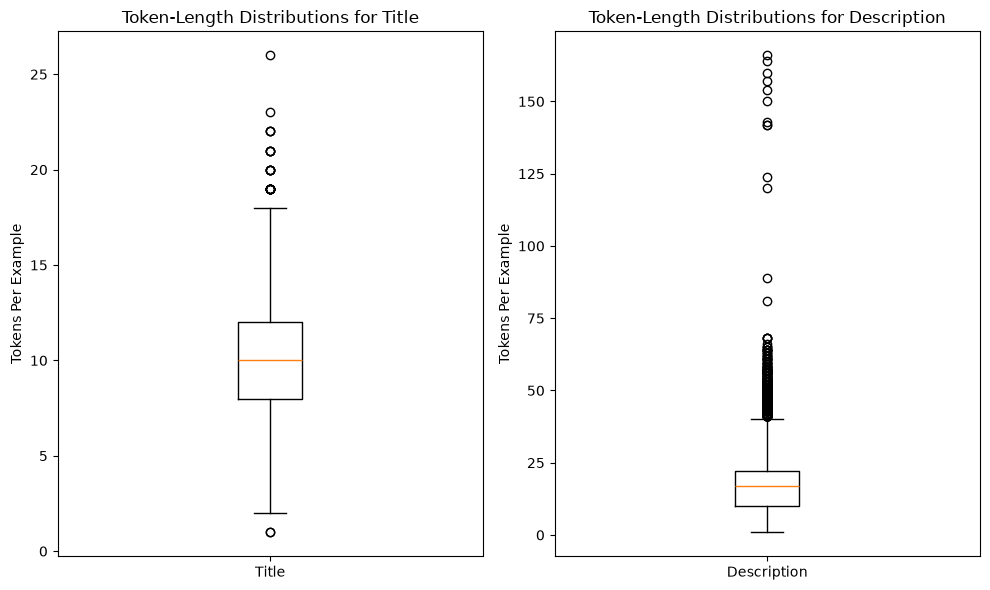

In [6]:
print(SOURCE_A_TRAIN.shape)
#7500 examples and 3 features

print(SOURCE_A_TRAIN[SOURCE_A_TRAIN["Label"] == 1].shape[0])
#1500 examples related to Politics

print(SOURCE_A_TRAIN[SOURCE_A_TRAIN["Label"] == 2].shape[0])
#1500 examples related to Sports

print(SOURCE_A_TRAIN[SOURCE_A_TRAIN["Label"] == 3].shape[0])
#1500 examples related to Business

print(SOURCE_A_TRAIN[SOURCE_A_TRAIN["Label"] == 4].shape[0])
#1500 examples related to Technology

print(SOURCE_A_TRAIN[SOURCE_A_TRAIN["Label"] == 5].shape[0])
#1500 examples related to Entertainment

print("Classes balanced:", SOURCE_A_TRAIN["Label"].value_counts().nunique() == 1)
#Check if every class has the same number of examples

print(SOURCE_A_TRAIN.isna().sum())
#Missing values per column

print("Empty titles:", (SOURCE_A_TRAIN["Title"].fillna("").str.strip() == "").sum())
print("Empty descriptions:", (SOURCE_A_TRAIN["Description"].fillna("").str.strip() == "").sum())
#Check for empty text

print("Duplicate rows:", SOURCE_A_TRAIN.duplicated().sum())
#Check for duplicate rows

SOURCE_A_TRAIN = SOURCE_A_TRAIN[SOURCE_A_TRAIN["Label"] != '']
SOURCE_A_TRAIN = SOURCE_A_TRAIN[SOURCE_A_TRAIN["Title"] != '']
SOURCE_A_TRAIN = SOURCE_A_TRAIN[SOURCE_A_TRAIN["Description"] != '']
#Drop rows that have empty text

SOURCE_A_TRAIN['title_tokens'] = SOURCE_A_TRAIN["Title"].str.split().str.len()
#Count Number of Tokens in Title (length is measured in whitespace-separated words)

SOURCE_A_TRAIN['description_tokens'] = SOURCE_A_TRAIN["Description"].str.split().str.len()
#Count Number of Tokens in Description

summary = SOURCE_A_TRAIN[["title_tokens", "description_tokens"]].describe()
print(summary)
#Token distribution length for title and description

fig, axes = plt.subplots(1, 2, figsize=(10, 6))
axes[0].boxplot(SOURCE_A_TRAIN["title_tokens"])
axes[0].set_xticklabels(["Title"])
axes[0].set_title('Token-Length Distributions for Title')
axes[0].set_ylabel("Tokens Per Example")

axes[1].boxplot(SOURCE_A_TRAIN["description_tokens"])
axes[1].set_xticklabels(["Description"])
axes[1].set_title('Token-Length Distributions for Description')
axes[1].set_ylabel("Tokens Per Example")

plt.tight_layout()
plt.show()

In [7]:
label_names = {
    1: "Politics",
    2: "Sports",
    3: "Business",
    4: "Technology",
    5: "Entertainment"
}

for label, class_name in label_names.items():
    example = SOURCE_A_TRAIN[
        SOURCE_A_TRAIN["Label"] == label
    ].sample(n=1, random_state=31)

    print(f"\nClass {label}: {class_name}")

    print("Title: " + example["Title"].iloc[0])
    print("Description: " + example["Description"].iloc[0])


Class 1: Politics
Title: Movement Against Juvenile Court Fees Runs Into Resistance
Description: In almost every state and the District of Columbia, the minors who appear in the roughly one million juvenile court cases

Class 2: Sports
Title: Lindsey Vonn Wins Bronze In What's Likely Her Last Olympic Downhill Race
Description: "I have no regrets; I’m really happy," she said.

Class 3: Business
Title: 10 Habits of Ultra-Likeable Leaders
Description: Becoming a more likable leader is completely under your control, and it's a matter of emotional intelligence (EQ). Unlike innate, fixed characteristics, such as your intelligence (IQ), EQ is a flexible skill that you can improve with effort.

Class 4: Technology
Title: Apple Accelerates Development Of Its Electric Car
Description: Apple Inc. is accelerating efforts to build an electric car, designating it internally as a “committed project” and setting

Class 5: Entertainment
Title: 5 Netflix Things To Watch If You Can't Wait For The Royal W

In [8]:
title_starts = SOURCE_A_TRAIN["Title"].str.split().str[:3].str.join(" ")
for label, class_name in label_names.items():
    print(f"\n{class_name}:")
    print(title_starts[SOURCE_A_TRAIN["Label"] == label].value_counts().head(5).to_string())
#Most common title openings per class, to look for formatting shortcuts


Politics:
Title
HuffPost Rise: What      13
HUFFPOST HILL -           8
Sunday Roundup            6
Donald Trump Is           5
Friday Talking Points     5

Sports:
Title
Former NFL Player        4
Golden State Warriors    4
High School Football     3
Tampa Bay Rays           3
Sport and Society        3

Business:
Title
Women in Business     14
Women in Business:    12
5 Ways to              4
These Are The          4
States With The        3

Technology:
Title
Watch The Top         50
WATCH: 60 Seconds      6
The Content Brief:     5
iPhone 5S Release      3
NY Tech Scene          3

Entertainment:
Title
'Game Of Thrones'       5
Weekend Box Office:     4
Friday Box Office       4
'This Is Us'            3
Jennifer Lawrence Is    2


In [9]:
# reload the original data so the Part 1 changes don't carry over
SOURCE_A_TRAIN = pd.read_csv("./dataset/dataset_a_train.csv")
SOURCE_A_TEST = pd.read_csv("./dataset/dataset_a_test.csv")
SOURCE_B_TEST = pd.read_csv("./dataset/dataset_b_test.csv")
SOURCE_C_TRAIN = pd.read_csv("./dataset/dataset_c_train.csv")
SOURCE_C_TEST = pd.read_csv("./dataset/dataset_c_test.csv")
print(SOURCE_A_TRAIN.shape, SOURCE_A_TEST.shape, SOURCE_B_TEST.shape, SOURCE_C_TRAIN.shape, SOURCE_C_TEST.shape)

(7500, 3) (2500, 3) (2225, 3) (6000, 3) (2000, 3)


## Part 2: Build an In-Domain Baseline on Data A

### Build a TF-IDF Table

In [10]:
# Set A
a_train, a_validation = train_test_split(
    SOURCE_A_TRAIN,
    test_size=0.2,
    random_state=0,
    stratify=SOURCE_A_TRAIN["Label"]  # label-stratified split
)

print(f"Training: {len(a_train)}, Validation: {len(a_validation)}")

Training: 6000, Validation: 1500


In [11]:
BATCH_SIZE = 32

In [12]:
vectorizer = TfidfVectorizer()  # default ngram_range is (1, 1), i.e. unigram

def concat_article(row):
    return row["Title"] + ' ' + row["Description"]

a_train_tfidf = vectorizer.fit_transform(a_train.apply(concat_article, axis=1))
a_validation_tfidf = vectorizer.transform(a_validation.apply(concat_article, axis=1))

a_train_tensor = torch.tensor(a_train_tfidf.toarray(), dtype=torch.float32).to(DEVICE)
a_validation_tensor = torch.tensor(a_validation_tfidf.toarray(), dtype=torch.float32).to(DEVICE)

# CrossEntropyLoss expects zero-indexed labels, so label - 1
a_train_labels_tensor = torch.tensor((a_train["Label"] - 1).to_list(), dtype=torch.long).to(DEVICE)
a_validation_labels_tensor = torch.tensor((a_validation["Label"] - 1).to_list(), dtype=torch.long).to(DEVICE)

In [13]:
a_train_dataset = TensorDataset(
    a_train_tensor.cpu(),
    a_train_labels_tensor.cpu()
)
a_validation_dataset = TensorDataset(
    a_validation_tensor.cpu(),
    a_validation_labels_tensor.cpu()
)

a_train_loader = DataLoader(
    a_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,  # ensure the training data is shuffled in every epoch
    pin_memory=USE_CUDA
)
a_validation_loader = DataLoader(
    a_validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    pin_memory=USE_CUDA
)

### Training Loop

In [14]:
import copy


def train(model, optimizer, max_epoch, patience=5):
    criterion = nn.CrossEntropyLoss()
    history = {"training_loss": [], "validation_loss": [], "training_accuracy": [], "validation_accuracy": []}
    best_loss, best_epoch, best_state, bad_epochs = float("inf"), 0, None, 0

    for epoch in range(max_epoch):
        # Training
        model.train()
        training_loss, training_correct = 0, 0

        for x, y in a_train_loader:
            x = x.to(DEVICE, non_blocking=True)
            y = y.to(DEVICE, non_blocking=True)

            logits = model(x)
            loss = criterion(logits, y)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            # multiply by batch size to get the total loss for this batch
            training_loss += loss.item() * x.size(0)
            training_correct += (logits.argmax(dim=1) == y).sum().item()

        # Validation
        model.eval()
        validation_loss, validation_correct = 0, 0

        with torch.inference_mode():
            for x, y in a_validation_loader:
                x = x.to(DEVICE, non_blocking=True)
                y = y.to(DEVICE, non_blocking=True)

                logits = model(x)
                validation_loss += criterion(logits, y).item() * x.size(0)
                validation_correct += (logits.argmax(dim=1) == y).sum().item()

        history["training_loss"].append(training_loss / len(a_train_dataset))
        history["validation_loss"].append(validation_loss / len(a_validation_dataset))
        history["training_accuracy"].append(training_correct / len(a_train_dataset))
        history["validation_accuracy"].append(validation_correct / len(a_validation_dataset))

        print(f"Epoch: {epoch + 1:02}/{max_epoch}  "
              f"train loss: {history['training_loss'][-1]:.4f}  val loss: {history['validation_loss'][-1]:.4f}  "
              f"val acc: {history['validation_accuracy'][-1]:.4f}")

        # early stopping on validation loss
        if history["validation_loss"][-1] < best_loss:
            best_loss, best_epoch, bad_epochs = history["validation_loss"][-1], epoch + 1, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            bad_epochs += 1
            if bad_epochs >= patience:
                print(f"Stopping early. Best epoch: {best_epoch}")
                break

    model.load_state_dict(best_state)
    return history, best_epoch


def plot_history(history, title, note):
    epochs = range(1, len(history["training_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(epochs, history["training_loss"], label="Training Loss")
    axes[0].plot(epochs, history["validation_loss"], label="Validation Loss")
    axes[0].set_ylabel("Loss")
    axes[0].set_title(f"Training & Validation Losses ({title})")

    axes[1].plot(epochs, history["training_accuracy"], label="Training Accuracy")
    axes[1].plot(epochs, history["validation_accuracy"], label="Validation Accuracy")
    axes[1].set_ylabel("Accuracy")
    axes[1].set_title(f"Training & Validation Accuracies ({title})")

    for ax in axes:
        ax.set_xlabel("Epoch")
        ax.legend()
    plt.figtext(1, 0, note, ha="right")
    plt.tight_layout()
    plt.show()

### Logistic Regressor

In [15]:
# Constants & Hyperparameters
LR_MAX_EPOCH = 50
LR_LEARNING_RATE = 0.01

Epoch: 01/50  train loss: 1.6088  val loss: 1.6079  val acc: 0.3013
Epoch: 02/50  train loss: 1.6072  val loss: 1.6064  val acc: 0.4220
Epoch: 03/50  train loss: 1.6055  val loss: 1.6049  val acc: 0.4860
Epoch: 04/50  train loss: 1.6039  val loss: 1.6033  val acc: 0.5427
Epoch: 05/50  train loss: 1.6023  val loss: 1.6018  val acc: 0.5760
Epoch: 06/50  train loss: 1.6006  val loss: 1.6003  val acc: 0.6080
Epoch: 07/50  train loss: 1.5990  val loss: 1.5988  val acc: 0.6393
Epoch: 08/50  train loss: 1.5973  val loss: 1.5973  val acc: 0.6513
Epoch: 09/50  train loss: 1.5957  val loss: 1.5958  val acc: 0.6620
Epoch: 10/50  train loss: 1.5941  val loss: 1.5942  val acc: 0.6680
Epoch: 11/50  train loss: 1.5925  val loss: 1.5927  val acc: 0.6767
Epoch: 12/50  train loss: 1.5909  val loss: 1.5912  val acc: 0.6820
Epoch: 13/50  train loss: 1.5892  val loss: 1.5897  val acc: 0.6853
Epoch: 14/50  train loss: 1.5876  val loss: 1.5882  val acc: 0.6853
Epoch: 15/50  train loss: 1.5860  val loss: 1.58

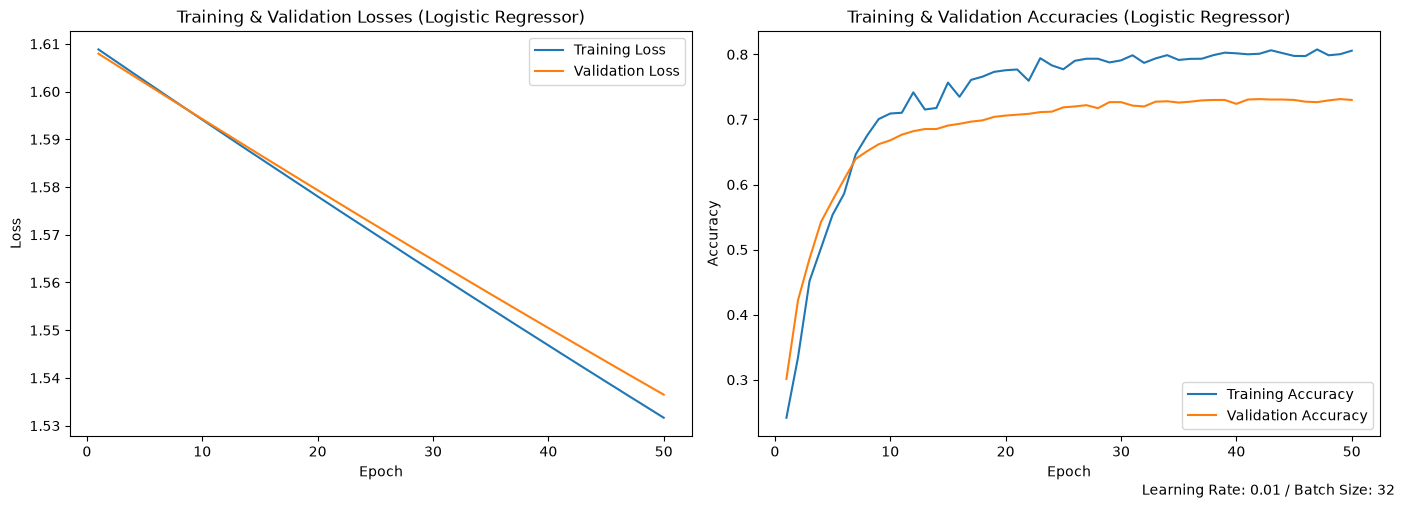

In [16]:
torch.manual_seed(0)
lr_model = torch.nn.Linear(a_train_tensor.shape[1], LABELS.shape[0]).to(DEVICE)
lr_optimizer = optim.SGD(lr_model.parameters(), lr=LR_LEARNING_RATE)

lr_history, lr_best_epoch = train(lr_model, lr_optimizer, LR_MAX_EPOCH)
plot_history(lr_history, "Logistic Regressor", f"Learning Rate: {LR_LEARNING_RATE} / Batch Size: {BATCH_SIZE}")

### Custom Multi-Layer Perceptron

The model consists of the following layers:
1. Input Layer: input_dim
2. Hidden Layer 1: 128 neurons $\to$ ReLU activation $\to$ Dropout (0.2)
3. Hidden Layer 2: 64 neurons $\to$ ReLU activation $\to$ Dropout (0.3)
4. Output Layer: output_dim (number of labels)

Loss Function: Cross-Entropy

Optimizer: SGD (learning rate 0.024, momentum 0.9, weight decay 0.001), batch size 32

Stopping Rule: up to 35 epochs, early stopping when validation loss doesn't improve for 5 epochs

In [17]:
class CustomMLP(nn.Module):
    def __init__(self, input_dim, output_dim):
        super().__init__()

        self.layers = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(64, output_dim)
        )

    def forward(self, x):
        return self.layers(x)

In [18]:
# Constants & Hyperparameters
MLP_MAX_EPOCH = 35
MLP_LEARNING_RATE = 0.024
MOMENTUM = 0.9
WEIGHT_DECAY = 0.001

Epoch: 01/35  train loss: 1.6110  val loss: 1.6093  val acc: 0.2000
Epoch: 02/35  train loss: 1.6100  val loss: 1.6084  val acc: 0.3247
Epoch: 03/35  train loss: 1.6062  val loss: 1.6017  val acc: 0.2000
Epoch: 04/35  train loss: 1.5878  val loss: 1.5567  val acc: 0.4647
Epoch: 05/35  train loss: 1.4551  val loss: 1.2881  val acc: 0.4880
Epoch: 06/35  train loss: 1.1931  val loss: 1.0654  val acc: 0.6180
Epoch: 07/35  train loss: 0.9178  val loss: 0.9788  val acc: 0.5833
Epoch: 08/35  train loss: 0.7012  val loss: 0.7935  val acc: 0.7007
Epoch: 09/35  train loss: 0.5629  val loss: 0.8186  val acc: 0.6860
Epoch: 10/35  train loss: 0.4536  val loss: 0.9592  val acc: 0.6807
Epoch: 11/35  train loss: 0.3556  val loss: 0.7115  val acc: 0.7513
Epoch: 12/35  train loss: 0.2868  val loss: 0.7945  val acc: 0.7600
Epoch: 13/35  train loss: 0.2389  val loss: 0.7120  val acc: 0.7627
Epoch: 14/35  train loss: 0.1643  val loss: 0.7777  val acc: 0.7447
Epoch: 15/35  train loss: 0.1165  val loss: 0.72

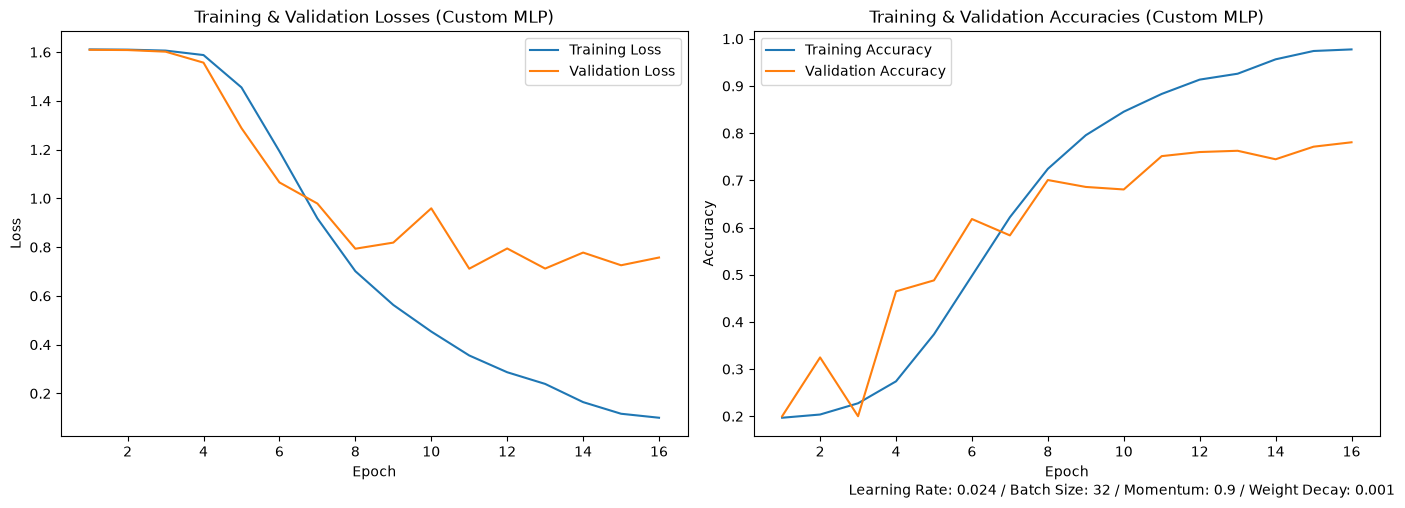

In [19]:
torch.manual_seed(0)
mlp_model = CustomMLP(a_train_tensor.shape[1], LABELS.shape[0]).to(DEVICE)
mlp_optimizer = optim.SGD(mlp_model.parameters(), lr=MLP_LEARNING_RATE, momentum=MOMENTUM, weight_decay=WEIGHT_DECAY)

mlp_history, mlp_best_epoch = train(mlp_model, mlp_optimizer, MLP_MAX_EPOCH)
plot_history(mlp_history, "Custom MLP",
             f"Learning Rate: {MLP_LEARNING_RATE} / Batch Size: {BATCH_SIZE} / Momentum: {MOMENTUM} / Weight Decay: {WEIGHT_DECAY}")

### Refit & Test

In [20]:
# refit the vectorizer on all of dataset_a_train.csv
full_vectorizer = TfidfVectorizer()
a_full_tfidf = full_vectorizer.fit_transform(SOURCE_A_TRAIN.apply(concat_article, axis=1))
a_test_tfidf = full_vectorizer.transform(SOURCE_A_TEST.apply(concat_article, axis=1))

a_full_dataset = TensorDataset(
    torch.tensor(a_full_tfidf.toarray(), dtype=torch.float32),
    torch.tensor((SOURCE_A_TRAIN["Label"] - 1).to_list(), dtype=torch.long)
)
a_test_dataset = TensorDataset(
    torch.tensor(a_test_tfidf.toarray(), dtype=torch.float32),
    torch.tensor((SOURCE_A_TEST["Label"] - 1).to_list(), dtype=torch.long)
)
a_full_loader = DataLoader(a_full_dataset, batch_size=BATCH_SIZE, shuffle=True, pin_memory=USE_CUDA)
a_test_loader = DataLoader(a_test_dataset, batch_size=BATCH_SIZE, shuffle=False, pin_memory=USE_CUDA)


# train for the best number of epochs found on validation
def refit(model, optimizer, epochs):
    criterion = nn.CrossEntropyLoss()
    for epoch in range(epochs):
        model.train()
        for x, y in a_full_loader:
            x = x.to(DEVICE, non_blocking=True)
            y = y.to(DEVICE, non_blocking=True)
            loss = criterion(model(x), y)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
    return model


def test(model):
    model.eval()
    predictions = []
    with torch.inference_mode():
        for x, _ in a_test_loader:
            predictions.extend(model(x.to(DEVICE)).argmax(dim=1).cpu().numpy() + 1)
    return np.array(predictions)


input_dim = a_full_tfidf.shape[1]

torch.manual_seed(0)
lr_final = torch.nn.Linear(input_dim, LABELS.shape[0]).to(DEVICE)
refit(lr_final, optim.SGD(lr_final.parameters(), lr=LR_LEARNING_RATE), lr_best_epoch)

torch.manual_seed(0)
mlp_final = CustomMLP(input_dim, LABELS.shape[0]).to(DEVICE)
refit(mlp_final, optim.SGD(mlp_final.parameters(), lr=MLP_LEARNING_RATE, momentum=MOMENTUM,
                           weight_decay=WEIGHT_DECAY), mlp_best_epoch)

display(pd.DataFrame([
    {"model": "Logistic Regressor", "representation": "unigram TF-IDF (title + description)", "optimizer": "SGD",
     "learning_rate": LR_LEARNING_RATE, "momentum": 0, "weight_decay": 0, "dropout": "none",
     "batch_size": BATCH_SIZE, "epochs": lr_best_epoch, "seed": 0, "train_size": len(SOURCE_A_TRAIN),
     "vocab_size": input_dim},
    {"model": "Custom MLP", "representation": "unigram TF-IDF (title + description)", "optimizer": "SGD",
     "learning_rate": MLP_LEARNING_RATE, "momentum": MOMENTUM, "weight_decay": WEIGHT_DECAY, "dropout": "(0.2, 0.3)",
     "batch_size": BATCH_SIZE, "epochs": mlp_best_epoch, "seed": 0, "train_size": len(SOURCE_A_TRAIN),
     "vocab_size": input_dim},
]))

,model,representation,optimizer,learning_rate,momentum,weight_decay,dropout,batch_size,epochs,seed,train_size,vocab_size
0,Logistic Regressor,unigram TF-IDF (title + description),SGD,0.010,0.0,0.000,none,32,50,0,7500,19834
1,Custom MLP,unigram TF-IDF (title + description),SGD,0.024,0.9,0.001,"(0.2, 0.3)",32,11,0,7500,19834


Logistic Regressor
Accuracy: 0.5156
Macro-F1: 0.5171
               precision    recall  f1-score   support

     Politics     0.3952    0.4260    0.4100       500
       Sports     0.5596    0.6200    0.5882       500
     Business     0.5230    0.5000    0.5112       500
   Technology     0.6690    0.5700    0.6156       500
Entertainment     0.4592    0.4620    0.4606       500

     accuracy                         0.5156      2500
    macro avg     0.5212    0.5156    0.5171      2500
 weighted avg     0.5212    0.5156    0.5171      2500

Custom MLP
Accuracy: 0.5464
Macro-F1: 0.5375
               precision    recall  f1-score   support

     Politics     0.4467    0.3100    0.3660       500
       Sports     0.5838    0.7800    0.6678       500
     Business     0.6193    0.5140    0.5617       500
   Technology     0.6603    0.6960    0.6777       500
Entertainment     0.3978    0.4320    0.4142       500

     accuracy                         0.5464      2500
    macro avg    

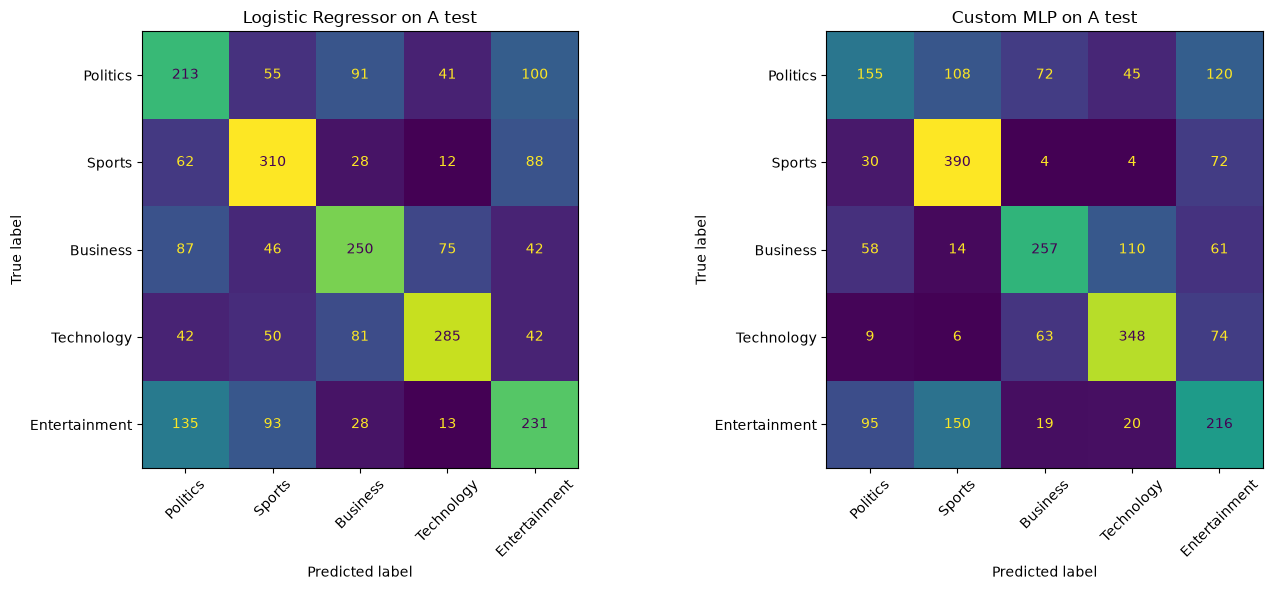

In [21]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score

a_test_labels = SOURCE_A_TEST["Label"].to_numpy()
class_names = list(LABELS["Set A"])
part2_predictions = {"Logistic Regressor": test(lr_final), "Custom MLP": test(mlp_final)}

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (name, pred) in zip(axes, part2_predictions.items()):
    print(name)
    print(f"Accuracy: {accuracy_score(a_test_labels, pred):.4f}")
    print(f"Macro-F1: {f1_score(a_test_labels, pred, average='macro'):.4f}")
    print(classification_report(a_test_labels, pred, labels=[1, 2, 3, 4, 5], target_names=class_names, digits=4))

    ConfusionMatrixDisplay(confusion_matrix(a_test_labels, pred, labels=[1, 2, 3, 4, 5]),
                           display_labels=class_names).plot(ax=ax, colorbar=False, xticks_rotation=45)
    ax.set_title(f"{name} on A test")
plt.tight_layout()
plt.show()

### Error Analysis

In [22]:
pd.set_option("display.max_colwidth", 150)

for name, pred in part2_predictions.items():
    wrong = pred != a_test_labels
    errors = SOURCE_A_TEST[wrong].assign(Predicted=pred[wrong])
    pairs = errors["Label"].map(LABELS["Set A"]) + " -> " + errors["Predicted"].map(LABELS["Set A"])

    print(f"{name}: {wrong.sum()} of {len(pred)} test articles misclassified")
    display(pairs.value_counts().head(6).to_frame("count"))
    display(errors.sample(10, random_state=0)[["Label", "Predicted", "Title", "Description"]])

Logistic Regressor: 1211 of 2500 test articles misclassified


,count
Entertainment -> Politics,135
Politics -> Entertainment,100
Entertainment -> Sports,93
Politics -> Business,91
Sports -> Entertainment,88
Business -> Politics,87


,Label,Predicted,Title,Description
392,2,5,U.S. Speedskater's 'Honorable Move' Allows Friend To Replace Her In Olympic Race,"Brittany Bowe stepped aside so Erin Jackson, who slipped in the trials, could skate the 500 meters in Beijing."
2031,4,3,15 Black Friday Laptop Deals Actually Worth Your Time And Money,There’s something on sale for every type of user 💻
104,5,1,'Scandal' Mirrors Trump's White House With Russian Interference And Controversial Memo,“Scandal” seemed all too familiar this week when White House Chief of Staff Olivia Pope was out and NSA Director Jake Ballard
1489,1,2,Texas Gov. Greg Abbott Loudly Booed At Uvalde Memorial,"""Shame on you, Abbott!"" a crowd member yelled as Abbott arrived with the Bidens at the school where 19 children and two teachers were killed."
705,4,5,"C-SPAN Broadcasts Periscope, Facebook Streams After Republicans Cut Off TV Cameras",This has never happened before.
2499,1,2,34 Schools In Louisiana Told By District That Athletes Should Stand For Anthem,It's a lawsuit waiting to happen.
1825,2,3,British Football Child Molestation Scandal: One Voice Spoke and Suddenly 500 More Kicked In,The most powerful 20 minutes of television Tuesday night are also likely to be the most somber: a catchup report for the
1922,4,2,Fired Google Engineer Blames Diversity Zealots For His Dismissal,"James Damore's Wall Street Journal essay decries ""public shaming."""
2272,3,1,Delta Under Fire After Pilot Appears To Hit Passenger,"The company has defended the employee, who it said was breaking up a fight."
1390,1,5,Lindsey Graham Scolded For Senate Outburst At Maggie Hassan,Graham directly insulted Hassan and presiding officer Chris Murphy (D-Conn.) stepped in.


Custom MLP: 1134 of 2500 test articles misclassified


,count
Entertainment -> Sports,150
Politics -> Entertainment,120
Business -> Technology,110
Politics -> Sports,108
Entertainment -> Politics,95
Technology -> Entertainment,74


,Label,Predicted,Title,Description
906,1,3,NY Gun Applicants Will Soon Have Social Media Accounts Screened,New York state is rolling out a novel strategy to screen applicants for gun permits.
2278,3,4,Leave This At Home When You Go Shopping (Or You'll Regret It),What should you leave at home when you go shopping this summer? Jennifer Boaro prefers this strategy: Put your credit cards
877,5,1,Hillary Clinton Hints At Racism In Media Mistreatment Of Meghan Markle,The former secretary of state and her daughter Chelsea staunchly defended the Duchess of Sussex amid the royal's lawsuit against a tabloid.
1198,1,5,"Sing, Paulie, Sing: Michael Rapaport Urges Manafort To Talk In Gleeful Video","""Whaddya got on Donald, huh?"" asks the ""Boston Public"" actor."
1048,3,5,"Facebook Finally Yanks Virtual Reality Shooting Game At CPAC, Apologizes","""Bullet Train"" featured players firing on virtual people in a train station just days after the Parkland high school shootings."
719,1,2,"Bears, Packers Link Arms During National Anthem",NFL players again stood in solidarity after President Donald Trump's call to fire players protesting racial injustice.
31,3,1,The Savings And Stability Of Public Banking,There needs to be much more education of state legislators and the public at large.
1726,3,4,Amazon And Whole Foods Disagree On Products Like Coca-Cola,The companies are having disagreements over what to stock on store shelves.
112,4,3,How In The World Does Venmo Make Money?,"The feature that sets Venmo apart is the social feed, which brings transparency to a class of transactions that used to be entirely private."
869,3,5,Takata Air Bag Defect Tied To Another Death,At least 16 deaths are now linked to the defect that prompted a recall of nearly 100 million air bag inflators.


Most of the errors fall into a few groups:

**Politics and Entertainment.** These get mixed up the most. A lot of political stories are about famous people, and a lot of entertainment stories mention politicians, so both classes end up sharing names and words.

**Business and Technology.** Articles about companies like Apple or Facebook can be about either one. Words like "company", "market", and "launch" show up in both classes, so the model has a hard time picking.

**Sports and Entertainment.** Stories about athletes outside of the actual games, like their personal lives or appearances on TV, read more like entertainment news.

**Descriptions with no topic words.** Some descriptions are just a quote, like the Part 1 sports example ("I have no regrets; I'm really happy," she said). When the title is also vague, there isn't much for TF-IDF to work with.

## Part 3: Study Regularization and Transfer to Data B

In [23]:
import copy
import os

from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score

SEED = 0
CLASS_IDS = [1, 2, 3, 4, 5]
NUM_CLASSES = len(CLASS_IDS)
MAX_EPOCHS = 30
PATIENCE = 5  # stop after 5 epochs without a better val macro-F1
P3_BATCH_SIZE = 64


def set_seed(seed=SEED):
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def article_text(df):
    return df["Title"].fillna("") + " " + df["Description"].fillna("")


y_a_full = SOURCE_A_TRAIN["Label"].to_numpy()
y_a_test = SOURCE_A_TEST["Label"].to_numpy()
y_b_test = SOURCE_B_TEST["Label"].to_numpy()

In [24]:
# same layers as CustomMLP, but the dropout can be changed
class RegMLP(nn.Module):
    def __init__(self, input_dim, output_dim, dropout=(0.2, 0.3)):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(input_dim, 128), nn.ReLU(), nn.Dropout(dropout[0]),
            nn.Linear(128, 64), nn.ReLU(), nn.Dropout(dropout[1]),
            nn.Linear(64, output_dim),
        )

    def forward(self, x):
        return self.layers(x)


def build_model(kind, input_dim, dropout=(0.0, 0.0)):
    if kind == "lr":
        return nn.Linear(input_dim, NUM_CLASSES)
    return RegMLP(input_dim, NUM_CLASSES, dropout)

In [25]:
def batches(X, y=None, shuffle=False, rng=None):
    idx = np.arange(X.shape[0])
    if shuffle:
        rng.shuffle(idx)
    for start in range(0, len(idx), P3_BATCH_SIZE):
        b = idx[start:start + P3_BATCH_SIZE]
        xb = torch.tensor(X[b].toarray(), dtype=torch.float32, device=DEVICE)
        if y is None:
            yield xb
        else:
            yield xb, torch.tensor(y[b], dtype=torch.long, device=DEVICE)


def predict(model, X):
    model.eval()
    with torch.inference_mode():
        preds = [model(xb).argmax(dim=1).cpu().numpy() for xb in batches(X)]
    return np.concatenate(preds) + 1  # back to labels 1-5


def evaluate(y_true, y_pred, labels=CLASS_IDS):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, labels=labels, average="macro", zero_division=0),
        "per_class": classification_report(y_true, y_pred, labels=labels, output_dict=True, zero_division=0),
        "confusion_matrix": confusion_matrix(y_true, y_pred, labels=labels),
    }


# with validation data it early stops on val macro-F1 and keeps the best epoch,
# without it it just trains for a fixed number of epochs (for the refit)
def train_model(kind, setting, X_train, y_train, X_val=None, y_val=None, epochs=MAX_EPOCHS):
    set_seed()
    rng = np.random.default_rng(SEED)
    model = build_model(kind, X_train.shape[1], setting.get("dropout", (0.0, 0.0))).to(DEVICE)
    optimizer = optim.Adam(model.parameters(), lr=setting["lr"], weight_decay=setting["weight_decay"])
    criterion = nn.CrossEntropyLoss()
    y_train = np.asarray(y_train) - 1

    best_f1, best_epoch, best_state, bad = -1.0, 0, None, 0
    history = []
    for epoch in range(1, epochs + 1):
        model.train()
        for xb, yb in batches(X_train, y_train, shuffle=True, rng=rng):
            loss = criterion(model(xb), yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        if X_val is None:
            continue
        val_f1 = evaluate(y_val, predict(model, X_val))["macro_f1"]
        history.append({"epoch": epoch, "val_macro_f1": val_f1})
        if val_f1 > best_f1:
            best_f1, best_epoch, bad = val_f1, epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            bad += 1
            if bad >= PATIENCE:
                break

    if X_val is None:
        return model, epochs, history
    model.load_state_dict(best_state)
    return model, best_epoch, history

### Regularization Settings

In [26]:
# LR: L2 penalty through weight decay
LR_SETTINGS = {
    "lr_wd0":    {"lr": 1e-2, "weight_decay": 0.0},
    "lr_wd1e-5": {"lr": 1e-2, "weight_decay": 1e-5},
    "lr_wd1e-4": {"lr": 1e-2, "weight_decay": 1e-4},
    "lr_wd1e-3": {"lr": 1e-2, "weight_decay": 1e-3},
}

# MLP: dropout and weight decay
MLP_SETTINGS = {
    "mlp_none":       {"lr": 1e-3, "weight_decay": 0.0,  "dropout": (0.0, 0.0)},
    "mlp_dropout":    {"lr": 1e-3, "weight_decay": 0.0,  "dropout": (0.2, 0.3)},
    "mlp_dropout_wd": {"lr": 1e-3, "weight_decay": 1e-4, "dropout": (0.2, 0.3)},
    "mlp_strong":     {"lr": 1e-3, "weight_decay": 1e-3, "dropout": (0.5, 0.5)},
}

ALL_SETTINGS = {**{k: ("lr", v) for k, v in LR_SETTINGS.items()},
                **{k: ("mlp", v) for k, v in MLP_SETTINGS.items()}}

In [27]:
def run_sweep(X_tr, X_val):
    rows, epochs, histories = [], {}, {}
    for name, (kind, setting) in ALL_SETTINGS.items():
        model, epochs[name], histories[name] = train_model(kind, setting, X_tr, y_tr, X_val, y_val)
        val = evaluate(y_val, predict(model, X_val))
        rows.append({"setting": name, "model": kind.upper(), "best_epoch": epochs[name],
                     "val_accuracy": val["accuracy"], "val_macro_f1": val["macro_f1"]})
    df = pd.DataFrame(rows)
    best = {tag: df.loc[df[df.model == tag.upper()].val_macro_f1.idxmax(), "setting"] for tag in ["lr", "mlp"]}
    return df, best, epochs, histories


def refit_and_test(make_vectorizer, best, epochs):
    vec = make_vectorizer()
    X_full = vec.fit_transform(article_text(SOURCE_A_TRAIN))
    X_a = vec.transform(article_text(SOURCE_A_TEST))
    X_b = vec.transform(article_text(SOURCE_B_TEST))
    models, results = {}, {}
    for tag, name in best.items():
        kind, setting = ALL_SETTINGS[name]
        models[tag], _, _ = train_model(kind, setting, X_full, y_a_full, epochs=epochs[name])
        results[tag] = {"A_test": evaluate(y_a_test, predict(models[tag], X_a)),
                        "B_test": evaluate(y_b_test, predict(models[tag], X_b))}
    return vec, models, results


def summary_table(results, best):
    return pd.DataFrame([{
        "model": tag.upper(), "setting": best[tag],
        "A_accuracy": r["A_test"]["accuracy"], "A_macro_f1": r["A_test"]["macro_f1"],
        "B_accuracy": r["B_test"]["accuracy"], "B_macro_f1": r["B_test"]["macro_f1"],
    } for tag, r in results.items()])


def plot_confusion(results, prefix=""):
    names = list(LABELS["Set A"])
    fig, axes = plt.subplots(2, 2, figsize=(14, 12))
    for i, tag in enumerate(["lr", "mlp"]):
        for j, ds in enumerate(["A_test", "B_test"]):
            ConfusionMatrixDisplay(results[tag][ds]["confusion_matrix"], display_labels=names).plot(
                ax=axes[i, j], colorbar=False, xticks_rotation=45)
            axes[i, j].set_title(f"{prefix}{tag.upper()} on {ds.replace('_', ' ')}")
    plt.tight_layout()
    plt.show()


def per_class_table(results):
    rows = []
    for tag, r in results.items():
        for label in CLASS_IDS:
            a, b = r["A_test"]["per_class"][str(label)], r["B_test"]["per_class"][str(label)]
            rows.append({"model": tag.upper(), "class": LABELS.loc[label, "Set A"],
                         "A_precision": a["precision"], "A_recall": a["recall"], "A_f1": a["f1-score"],
                         "B_precision": b["precision"], "B_recall": b["recall"], "B_f1": b["f1-score"]})
    return pd.DataFrame(rows)


def config_table(best, epochs, representation, vec):
    rows = []
    for tag, name in best.items():
        kind, setting = ALL_SETTINGS[name]
        rows.append({"model": tag.upper(), "setting": name, "representation": representation,
                     "optimizer": "Adam", "learning_rate": setting["lr"], "weight_decay": setting["weight_decay"],
                     "dropout": str(setting.get("dropout", "none")), "batch_size": P3_BATCH_SIZE,
                     "epochs": epochs[name], "seed": SEED, "train_size": len(SOURCE_A_TRAIN),
                     "vocab_size": len(vec.vocabulary_)})
    return pd.DataFrame(rows)

### Validation Sweep

In [28]:
# same split as Part 2
p3_train, p3_val = train_test_split(SOURCE_A_TRAIN, test_size=0.2, random_state=SEED, stratify=SOURCE_A_TRAIN["Label"])
y_tr, y_val = p3_train["Label"].to_numpy(), p3_val["Label"].to_numpy()

p3_vectorizer = TfidfVectorizer()
X_tr = p3_vectorizer.fit_transform(article_text(p3_train))
X_val = p3_vectorizer.transform(article_text(p3_val))

sweep_df, best, best_epochs, histories = run_sweep(X_tr, X_val)
selection = {"selected_lr": best["lr"], "selected_mlp": best["mlp"]}

display(sweep_df)
print(f"Selected LR: {best['lr']} ({best_epochs[best['lr']]} epochs)")
print(f"Selected MLP: {best['mlp']} ({best_epochs[best['mlp']]} epochs)")

,setting,model,best_epoch,val_accuracy,val_macro_f1
0,lr_wd0,LR,4,0.810000,0.810021
1,lr_wd1e-5,LR,6,0.810000,0.810313
2,lr_wd1e-4,LR,5,0.805333,0.806006
3,lr_wd1e-3,LR,1,0.785333,0.785671
4,mlp_none,MLP,2,0.802000,0.802496
5,mlp_dropout,MLP,2,0.804000,0.804527
6,mlp_dropout_wd,MLP,2,0.797333,0.797937
7,mlp_strong,MLP,9,0.792000,0.792338


Selected LR: lr_wd1e-5 (6 epochs)
Selected MLP: mlp_dropout (2 epochs)


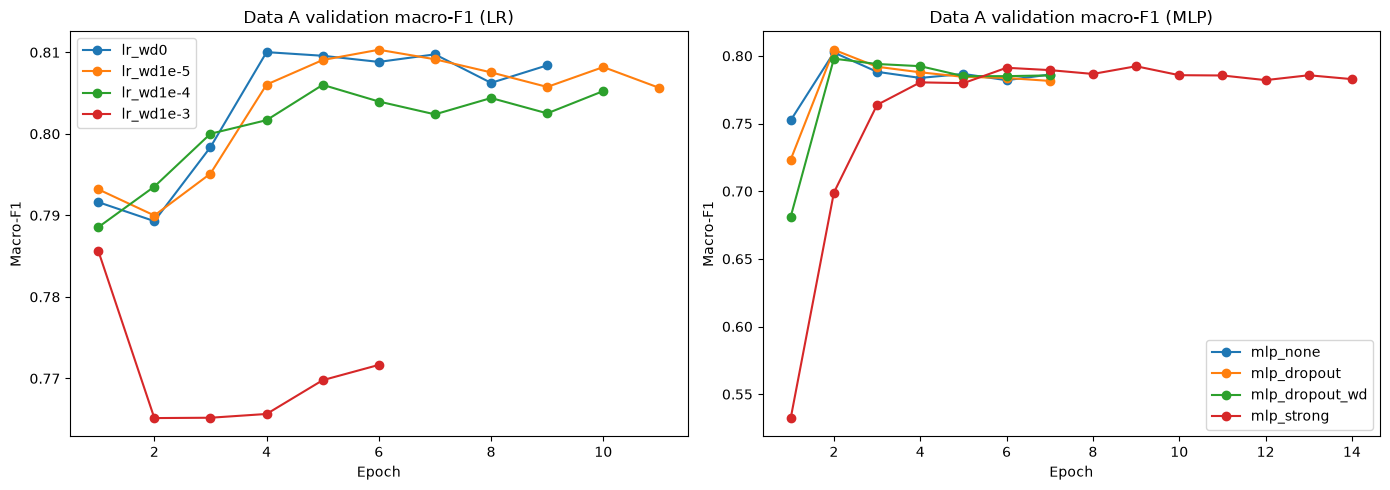

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, kind in zip(axes, ["lr", "mlp"]):
    for name, (k, _) in ALL_SETTINGS.items():
        if k == kind:
            h = pd.DataFrame(histories[name])
            ax.plot(h["epoch"], h["val_macro_f1"], marker="o", label=name)
    ax.set_title(f"Data A validation macro-F1 ({kind.upper()})")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Macro-F1")
    ax.legend()
plt.tight_layout()
plt.show()

### Refit & Test on Data A and Data B

In [30]:
vec_full, FINAL_MODELS, final_results = refit_and_test(TfidfVectorizer, best, best_epochs)
display(config_table(best, best_epochs, "unigram TF-IDF (title + description)", vec_full))
display(summary_table(final_results, best))

,model,setting,representation,optimizer,learning_rate,weight_decay,dropout,batch_size,epochs,seed,train_size,vocab_size
0,LR,lr_wd1e-5,unigram TF-IDF (title + description),Adam,0.010,0.00001,none,64,6,0,7500,19834
1,MLP,mlp_dropout,unigram TF-IDF (title + description),Adam,0.001,0.00000,"(0.2, 0.3)",64,2,0,7500,19834


,model,setting,A_accuracy,A_macro_f1,B_accuracy,B_macro_f1
0,LR,lr_wd1e-5,0.5648,0.564727,0.780225,0.788776
1,MLP,mlp_dropout,0.5784,0.574852,0.792360,0.794088


,model,class,A_precision,A_recall,A_f1,B_precision,B_recall,B_f1
0,LR,Politics,0.383,0.374,0.379,0.938,0.542,0.687
1,LR,Sports,0.652,0.664,0.658,0.982,0.871,0.923
2,LR,Business,0.612,0.564,0.587,0.527,0.990,0.688
3,LR,Technology,0.683,0.684,0.683,0.981,0.643,0.777
4,LR,Entertainment,0.497,0.538,0.517,0.977,0.782,0.869
5,MLP,Politics,0.404,0.372,0.388,0.874,0.468,0.609
6,MLP,Sports,0.667,0.696,0.681,0.983,0.896,0.938
7,MLP,Business,0.612,0.552,0.580,0.556,0.986,0.711
8,MLP,Technology,0.662,0.748,0.702,0.931,0.746,0.828
9,MLP,Entertainment,0.522,0.524,0.523,0.990,0.798,0.884


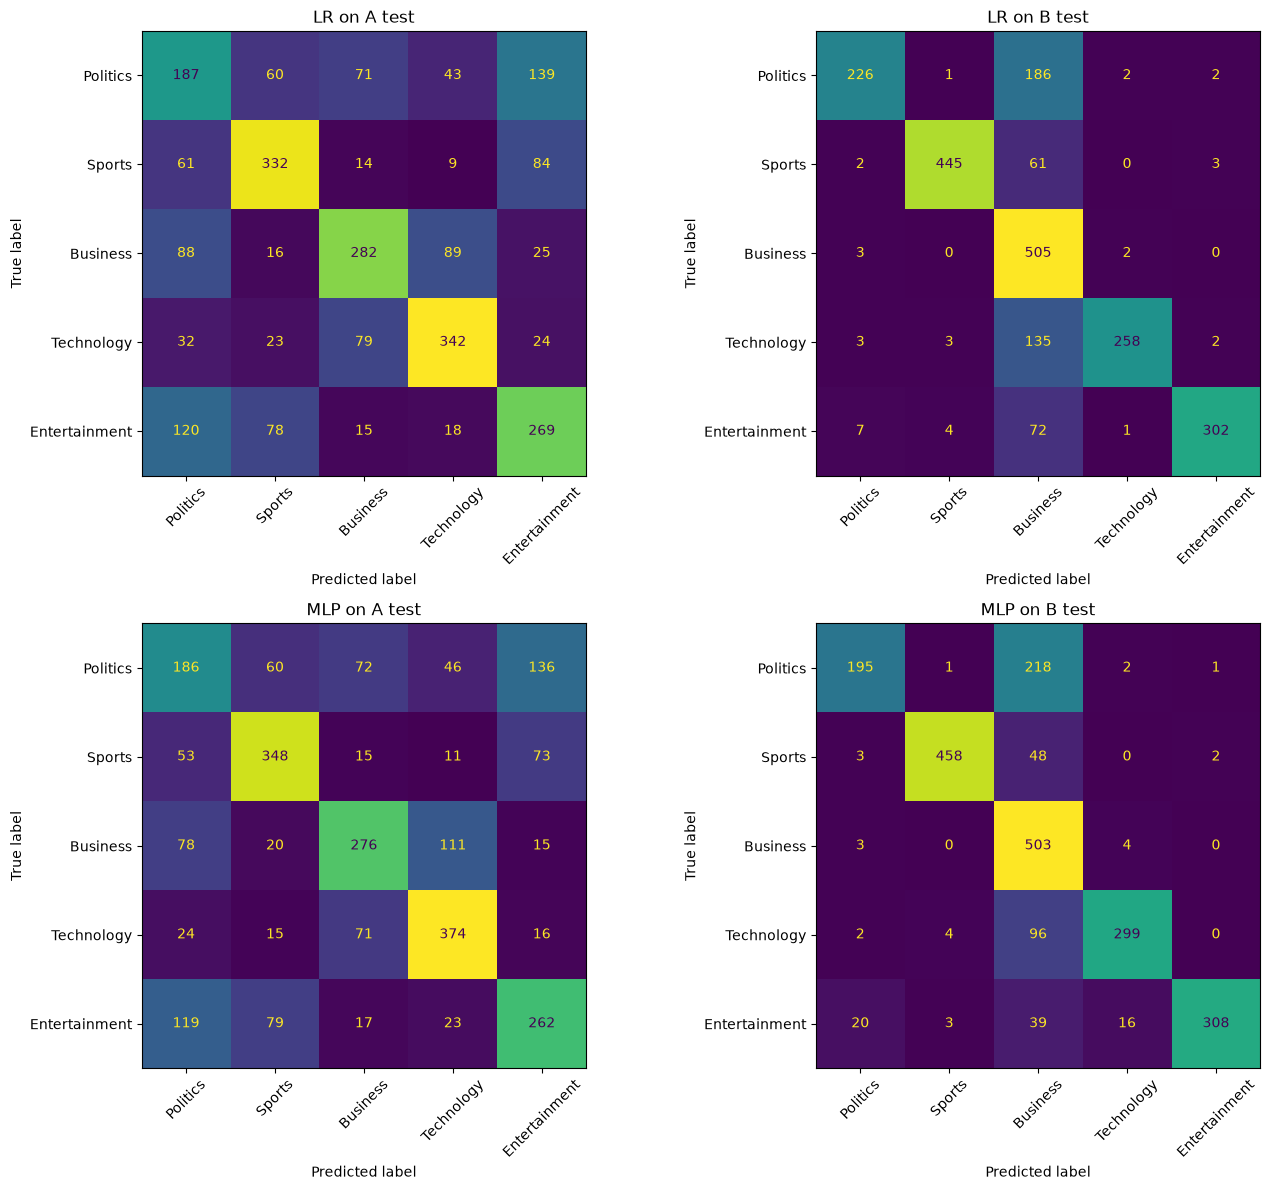

In [31]:
display(per_class_table(final_results).round(3))

plot_confusion(final_results)

### All Settings on the Test Sets (post hoc)

In [32]:
# only for analysis, not used to pick the final models
X_a_full = vec_full.transform(article_text(SOURCE_A_TRAIN))
X_a_test = vec_full.transform(article_text(SOURCE_A_TEST))
X_b_test = vec_full.transform(article_text(SOURCE_B_TEST))

posthoc = []
for name, (kind, setting) in ALL_SETTINGS.items():
    model, _, _ = train_model(kind, setting, X_a_full, y_a_full, epochs=best_epochs[name])
    posthoc.append({"setting": name,
                    "A_macro_f1": evaluate(y_a_test, predict(model, X_a_test))["macro_f1"],
                    "B_macro_f1": evaluate(y_b_test, predict(model, X_b_test))["macro_f1"]})
display(pd.DataFrame(posthoc).round(4))

,setting,A_macro_f1,B_macro_f1
0,lr_wd0,0.5599,0.7864
1,lr_wd1e-5,0.5647,0.7888
2,lr_wd1e-4,0.5626,0.7597
3,lr_wd1e-3,0.5472,0.5494
4,mlp_none,0.5749,0.8230
5,mlp_dropout,0.5749,0.7941
6,mlp_dropout_wd,0.5723,0.7797
7,mlp_strong,0.5521,0.7349


### Data A vs Data B

In [33]:
analyzer = vec_full.build_analyzer()
rows = []
for name, df in [("A train", SOURCE_A_TRAIN), ("A test", SOURCE_A_TEST), ("B test", SOURCE_B_TEST)]:
    tokens = [t for doc in article_text(df) for t in analyzer(doc)]
    rows.append({
        "dataset": name, "n": len(df),
        **{f"% label {k}": round(100 * (df["Label"] == k).mean(), 1) for k in CLASS_IDS},
        "median title words": df["Title"].str.split().str.len().median(),
        "median description words": df["Description"].str.split().str.len().median(),
        "% words not in A vocab": round(100 * np.mean([t not in vec_full.vocabulary_ for t in tokens]), 2),
    })
display(pd.DataFrame(rows))

# checking if duplicates explain the gap between validation and A test
train_text = set(article_text(p3_train))
print("duplicate rows in A train:", SOURCE_A_TRAIN.duplicated().sum())
print("val articles also in the train split:", article_text(p3_val).isin(train_text).sum(), "/", len(p3_val))
print("A test articles also in A train:", article_text(SOURCE_A_TEST).isin(set(article_text(SOURCE_A_TRAIN))).sum())

,dataset,n,% label 1,% label 2,% label 3,% label 4,% label 5,median title words,median description words,% words not in A vocab
0,A train,7500,20.0,20.0,20.0,20.0,20.0,10.0,17.0,0.00
1,A test,2500,20.0,20.0,20.0,20.0,20.0,11.0,15.0,5.28
2,B test,2225,18.7,23.0,22.9,18.0,17.3,5.0,326.0,7.36


duplicate rows in A train: 47
val articles also in the train split: 15 / 1500
A test articles also in A train: 0


## Part 4: Transfer to Data C and Analysis of Label 1
We use the two frozen Part 3 models (`FINAL_MODELS`) and the Part 3 vectorizer (`vec_full`) on `dataset_c_test.csv`. The vectorizer only calls `transform`, so nothing is refit on Data C.

In [34]:
# Data C test labels and features (Data A vocabulary with only transform)
c_test_labels = SOURCE_C_TEST["Label"].to_numpy()
print("C test size:", len(SOURCE_C_TEST))
print(SOURCE_C_TEST["Label"].value_counts().sort_index())

X_c_test = vec_full.transform(article_text(SOURCE_C_TEST))

# predictions from the frozen Part 3 models includin labels 1-5
lr_pred_c = predict(FINAL_MODELS["lr"], X_c_test)
mlp_pred_c = predict(FINAL_MODELS["mlp"], X_c_test)
part4_predictions = {"LR": lr_pred_c, "MLP": mlp_pred_c}

# check that no Data C test article also shows up in a training file
print("C test articles also in A train:", article_text(SOURCE_C_TEST).isin(article_text(SOURCE_A_TRAIN)).sum())
print("C test articles also in C train:", article_text(SOURCE_C_TEST).isin(article_text(SOURCE_C_TRAIN)).sum())

C test size: 2000
Label
1    500
2    500
3    500
4    500
Name: count, dtype: int64
C test articles also in A train: 0
C test articles also in C train: 0


### Shared labels (2-4), label 1, and label 5
Labels 2-4 mean the same thing in Data A and Data C, so we score them directly on the rows whose true label is 2, 3 or 4. Label 1 is Politics in Data A but World in Data C, so we look at it separately.

In [36]:
from sklearn.metrics import precision_score, recall_score

shared = (c_test_labels >= 2) & (c_test_labels <= 4)   # true label is 2, 3 or 4
is_world = c_test_labels == 1                          # true label is 1 (World)

rows = []
for name, pred in part4_predictions.items():
    rows.append({
        "model": name,
        "shared accuracy (2-4)": accuracy_score(c_test_labels[shared], pred[shared]),
        "shared macro-F1 (2-4)": f1_score(c_test_labels[shared], pred[shared], labels=[2, 3, 4], average="macro"),
        "label 1 precision": precision_score(is_world, pred == 1),
        "label 1 recall": recall_score(is_world, pred == 1),
        "label 1 F1": f1_score(is_world, pred == 1),
        "% predicted label 5": 100 * np.mean(pred == 5),
    })
display(pd.DataFrame(rows).round(4))

world_counts = pd.DataFrame(index=[1, 2, 3, 4, 5])
for name, pred in part4_predictions.items():
    world_counts[name] = pd.Series(pred[is_world]).value_counts()
world_counts = world_counts.fillna(0).astype(int)
world_counts.index.name = "predicted label"
print("Predictions for the true World (label 1) articles:")
display(world_counts)

,model,shared accuracy (2-4),shared macro-F1 (2-4),label 1 precision,label 1 recall,label 1 F1,% predicted label 5
0,LR,0.5867,0.6286,0.5923,0.430,0.4983,6.95
1,MLP,0.5987,0.6378,0.6068,0.392,0.4763,5.50


Predictions for the true World (label 1) articles:


,LR,MLP
predicted label,,
1,215,196
2,72,59
3,127,161
4,32,42
5,54,42


LR
               precision    recall  f1-score   support

        World     0.5923    0.4300    0.4983       500
       Sports     0.7804    0.8460    0.8119       500
     Business     0.4421    0.5120    0.4745       500
   Technology     0.5332    0.4020    0.4584       500
Entertainment     0.0000    0.0000    0.0000         0

     accuracy                         0.5475      2000
    macro avg     0.4696    0.4380    0.4486      2000
 weighted avg     0.5870    0.5475    0.5608      2000

MLP
               precision    recall  f1-score   support

        World     0.6068    0.3920    0.4763       500
       Sports     0.8102    0.8280    0.8190       500
     Business     0.4157    0.5180    0.4613       500
   Technology     0.5196    0.4500    0.4823       500
Entertainment     0.0000    0.0000    0.0000         0

     accuracy                         0.5470      2000
    macro avg     0.4705    0.4376    0.4478      2000
 weighted avg     0.5881    0.5470    0.5597      200

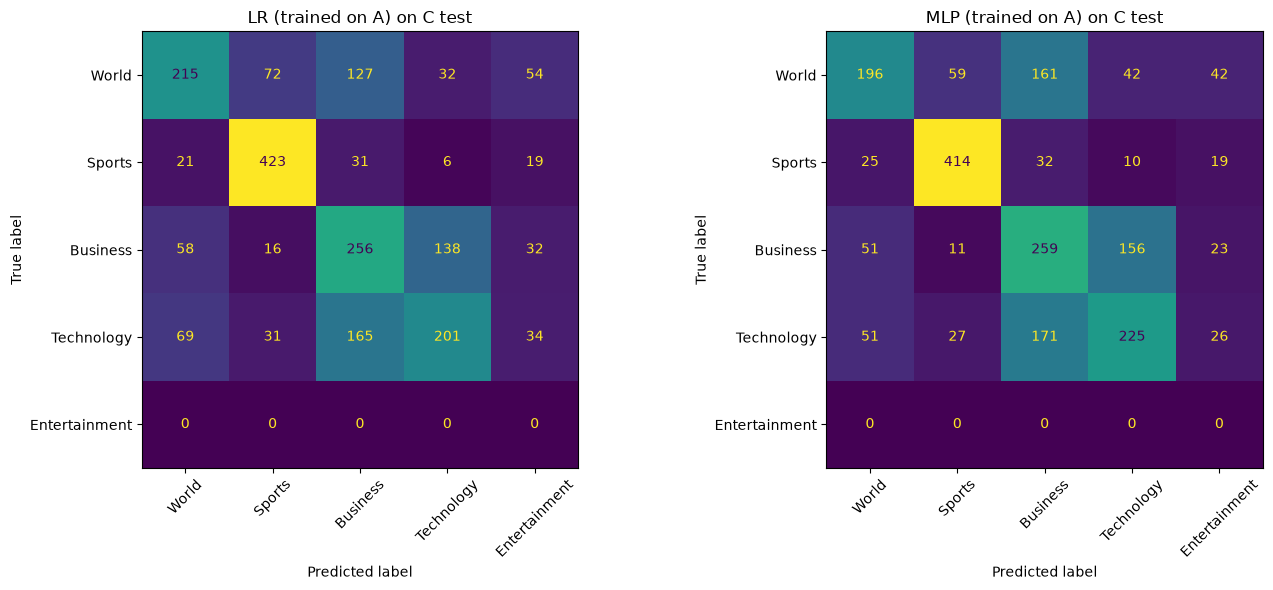

In [37]:
# full per-class report and confusion matrix for each model
# Data C has no label 5, so the Entertainment row should be all zeros
c_names = ["World", "Sports", "Business", "Technology", "Entertainment"]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (name, pred) in zip(axes, part4_predictions.items()):
    print(name)
    print(classification_report(c_test_labels, pred, labels=[1, 2, 3, 4, 5], target_names=c_names, digits=4, zero_division=0))

    cm = confusion_matrix(c_test_labels, pred, labels=[1, 2, 3, 4, 5])
    ConfusionMatrixDisplay(cm, display_labels=c_names).plot(ax=ax, colorbar=False, xticks_rotation=45)
    ax.set_title(f"{name} (trained on A) on C test")
plt.tight_layout()
plt.show()

### Errors on true label 1 (World)
A sample of World articles each model got wrong, then the words that show up in World articles both models missed but never appear in a Data A Politics training article.

In [38]:
pd.set_option("display.max_colwidth", 200)

for name, pred in part4_predictions.items():
    missed = is_world & (pred != 1)
    errors = SOURCE_C_TEST[missed].copy()
    errors["Predicted"] = pred[missed]
    print(f"{name}: {missed.sum()} of {is_world.sum()} World articles misclassified")
    display(errors.sample(12, random_state=0)[["Predicted", "Title", "Description"]])

LR: 285 of 500 World articles misclassified


,Predicted,Title,Description
429,5,Killing of Filmmaker Yields Indictments in Netherlands,"Description: Dutch authorities have indicted seven people in murder of a provocative filmmaker. Theo Van Gogh made films critical of Islamic violence against women and insulted Christians, Jews an..."
1198,5,Spice Isle in ruins,"BRIDGETOWN, Barbados - There are reports that at least 12 people were killed and 90 per cent of all homes in Grenada have been destroyed by Hurricane Ivan which has left quot;incalculable destruc..."
730,3,"Communism, capitalism forge throngs in Bucharest","BUCHAREST, Romania -- No parking spaces. Crippling traffic jams. Sky-high rents. Is this London, Rome, or Athens? No, it's Bucharest, where communism and capitalism have conspired to make it Europ..."
1373,2,China Olympians return as heroes,"Crowds of well wishers greet the Chinese Olympic team, returning home with a record number of medals."
1259,3,Dravid and Gambhir plunder Bangladesh (Reuters),Reuters - Rahul Dravid and Gautam Gambhir lashed big hundreds as India piled up 334 for two on the opening day of the second and final test against Bangladesh on Friday.
350,5,Tired pope beatifies Mel Gibon #39;s quot;muse quot;,"road to sainthood, including the 19th century German mystic nun who inspired Mel Gibson #39;s film on Christ #39;s passion. At the same ceremony in St Peter #39;s Square on Sunday, he beatified Au..."
858,3,The Berlin Wall: 15 years on,"It may be 15 years to the day since the Berlin Wall fell, but quot;die Mauer im Kopf quot; (literally, the wall in the head) is still there for many Germans."
1609,3,Child mortality rate drops in Latin America: UNICEF,"Latin America has seen a decline in child mortality rate, but the situation in Iraq, countries of the former Soviet Union and those in sub-Saharan Africa has worsened over the"
149,3,OPEC Hawks Want to Keep Prices High,"Raise prices. Ease production. For weeks ahead of this week's OPEC meeting, hawks in the organization have been talking tough about the need to keep oil revenues high - and lowering output."
211,5,Long-Lost Hendrix Concert Tape Discovered,"STOCKHOLM, Sweden - Technicians at Sweden's public television have unearthed an unexpected delight for music lovers - a complete original recording of a Jimi Hendrix concert in Stockholm from 1969..."


MLP: 304 of 500 World articles misclassified


,Predicted,Title,Description
532,2,Thorpedo Sinks Phelps' Shot at Record,"ATHENS, Greece - The kid couldn't catch the Thorpedo - and he won't be catching Mark Spitz, either. Michael Phelps' quest for seven gold medals ended after just three events, doomed by another bro..."
1103,3,Suicide bomb blasts Green Zone,"A SUICIDE car bomb has ripped through a line of vehicles at a checkpoint outside the Green Zone today, killing 13 people as Iraq marked the first anniversary of Saddam Hussein #39;s capture."
1609,3,Child mortality rate drops in Latin America: UNICEF,"Latin America has seen a decline in child mortality rate, but the situation in Iraq, countries of the former Soviet Union and those in sub-Saharan Africa has worsened over the"
1731,2,Spain handed Madrid bomb suspect,An Egyptian man suspected of playing a key role in the Madrid train bombings has been handed over to Spain.
1047,2,Cricket: England players' dismay,"England's players claim to have been used as ""political pawns"" over the Zimbabwe tour crisis."
995,2,Tsunami disaster overshadows India's ATP season-opener (AFP),AFP - Generating relief funds for tsunami victims and gearing up for the new season is the players' aim as they prepare for the ATP Chennai Open.
641,4,N.H. Man Denies FTC 'Spyware' Charges (AP),AP - The man at the center of the nation's first spyware case #151; a businessman notorious for his junk Internet mailings #151; says federal regulators were politically motivated in targeting h...
1010,2,It's October and It's Time for Playoffs!,Curt Schilling and Pedro Martinez are revved up. Roger Clemens and Roy Oswalt are rarin' to go...
825,4,ETA lets off small bombs in seven Spanish cities,On the anniversary of the Spanish Constitution yesterday ETA let off seven small explosive devices in as many Spanish cities. The blasts took place almost simultaneously at around 13.30 hours in S...
1146,3,EU ministers fail to resolve issue of transit camps,FLORENCE: Interior ministers from France and Spain on Monday shot down a German proposal to set up transit camps in North Africa to process asylum seekers before they reach Europe.


In [39]:
# split text into words with TF-IDF vectorizer
analyzer = vec_full.build_analyzer()

# every word that appears in a Data A Politics training article
politics_words = set()
for text in article_text(SOURCE_A_TRAIN[SOURCE_A_TRAIN["Label"] == 1]):
    politics_words.update(analyzer(text))

# count words in the World articles both models missed, if the word never appears in A Politics
missed_by_both = is_world & (lr_pred_c != 1) & (mlp_pred_c != 1)
word_counts = {}
for text in article_text(SOURCE_C_TEST[missed_by_both]):
    for word in set(analyzer(text)):   # set() so each article only counts a word once
        if word not in politics_words:
            word_counts[word] = word_counts.get(word, 0) + 1

print(missed_by_both.sum(), "World articles were missed by both models")
top_words = pd.Series(word_counts).sort_values(ascending=False).head(25)
display(top_words.to_frame("missed articles containing the word"))

270 World articles were missed by both models


,missed articles containing the word
afp,22
prices,15
european,13
quot,11
yesterday,11
eu,11
australia,10
japan,10
india,10
athens,8


### In-domain reference models trained on `dataset_c_train.csv`
Same selected Part 3 settings. We split Data C train 80/20, fit a new vectorizer on the training part, and early stop on the validation part. The best-epoch model is evaluated once on Data C test. These models are kept separate from the transferred models.

In [52]:
# 80/20 split of Data C train, same as Part 2
c_train, c_validation = train_test_split(SOURCE_C_TRAIN, test_size=0.2, random_state=0, stratify=SOURCE_C_TRAIN["Label"])

# new vectorizer fit only on the Data C training split
c_vectorizer = TfidfVectorizer()
Xc_train = c_vectorizer.fit_transform(article_text(c_train))
Xc_validation = c_vectorizer.transform(article_text(c_validation))
Xc_test = c_vectorizer.transform(article_text(SOURCE_C_TEST))

reference_predictions = {}
for name, setting_name in [("LR", best["lr"]), ("MLP", best["mlp"])]:
    kind, setting = ALL_SETTINGS[setting_name]
    model, best_epoch, _ = train_model(kind, setting, Xc_train, c_train["Label"].to_numpy(), Xc_validation, c_validation["Label"].to_numpy())
    reference_predictions[name] = predict(model, Xc_test)
    print(f"{name} reference: {setting_name}, best epoch {best_epoch}, "f"train size {len(c_train)}, vocab size {Xc_train.shape[1]}, seed 0")

LR reference: lr_wd1e-5, best epoch 14, train size 4800, vocab size 17303, seed 0
MLP reference: mlp_dropout, best epoch 8, train size 4800, vocab size 17303, seed 0


,model,source,label 1 recall,label 1 F1,macro-F1 (1-4)
0,LR,trained on A (transfer),0.430,0.4983,0.5608
1,LR,trained on C (reference),0.560,0.6080,0.6316
2,MLP,trained on A (transfer),0.392,0.4763,0.5597
3,MLP,trained on C (reference),0.580,0.6257,0.6409


LR reference
              precision    recall  f1-score   support

       World     0.6651    0.5600    0.6080       500
      Sports     0.7947    0.9060    0.8467       500
    Business     0.5321    0.4980    0.5145       500
  Technology     0.5360    0.5800    0.5572       500

    accuracy                         0.6360      2000
   macro avg     0.6320    0.6360    0.6316      2000
weighted avg     0.6320    0.6360    0.6316      2000

MLP reference
              precision    recall  f1-score   support

       World     0.6792    0.5800    0.6257       500
      Sports     0.8035    0.9240    0.8595       500
    Business     0.5333    0.5120    0.5224       500
  Technology     0.5463    0.5660    0.5560       500

    accuracy                         0.6455      2000
   macro avg     0.6406    0.6455    0.6409      2000
weighted avg     0.6406    0.6455    0.6409      2000



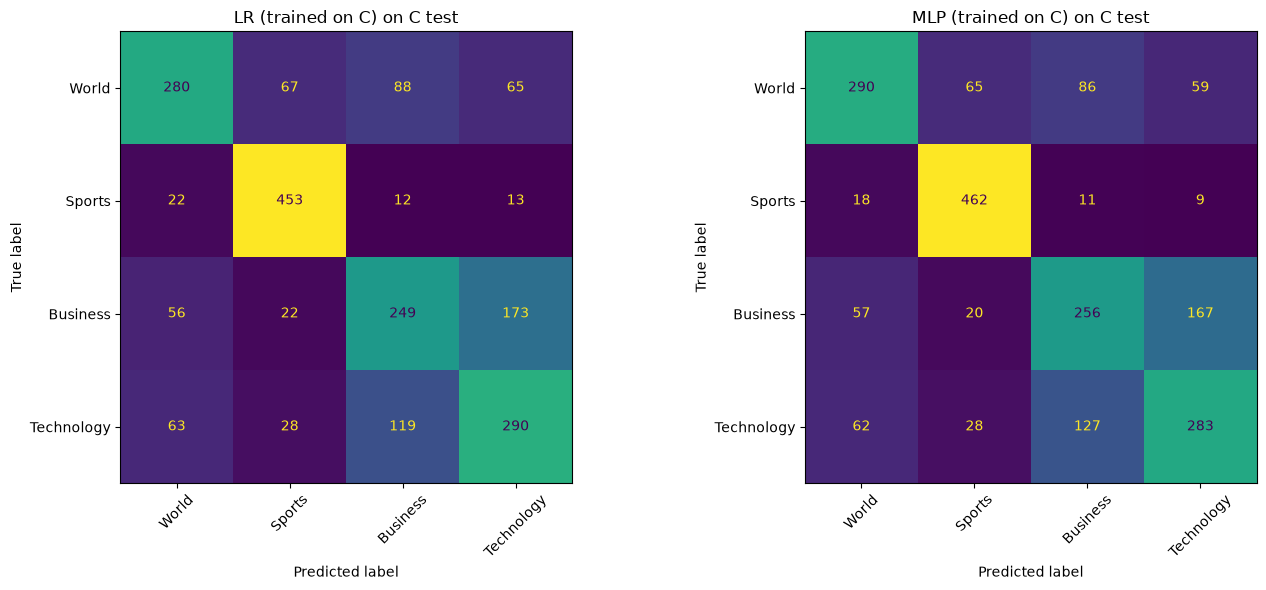

In [53]:
# compare the transferred Data A models with the Data C reference models
rows = []
for name in ["LR", "MLP"]:
    for source, pred in [("trained on A (transfer)", part4_predictions[name]), ("trained on C (reference)", reference_predictions[name])]:
        rows.append({
            "model": name,
            "source": source,
            "label 1 recall": recall_score(is_world, pred == 1),
            "label 1 F1": f1_score(is_world, pred == 1),
            "macro-F1 (1-4)": f1_score(c_test_labels, pred, labels=[1, 2, 3, 4], average="macro"),
        })
display(pd.DataFrame(rows).round(4))

# per-class report and confusion matrix for the reference models
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (name, pred) in zip(axes, reference_predictions.items()):
    print(name, "reference")
    print(classification_report(c_test_labels, pred, labels=[1, 2, 3, 4], target_names=c_names[:4], digits=4))

    cm = confusion_matrix(c_test_labels, pred, labels=[1, 2, 3, 4])
    ConfusionMatrixDisplay(cm, display_labels=c_names[:4]).plot(ax=ax, colorbar=False, xticks_rotation=45)
    ax.set_title(f"{name} (trained on C) on C test")

plt.tight_layout()
plt.show()

## Part 5: Add Limited Data C Training Examples

In [54]:
BUDGETS = [50, 150, 600, 1500]
STRATEGIES = {
    "label1_only": [1],          # World only
    "shared_only": [2, 3, 4],    # Sports, Business, Tech
    "balanced":    [1, 2, 3, 4],
}

FINAL = {tag: (*ALL_SETTINGS[name], best_epochs[name]) for tag, name in best.items()}

# shuffle each class once and take the first n rows, so smaller samples are subsets of bigger ones
C_POOLS = {label: SOURCE_C_TRAIN[SOURCE_C_TRAIN["Label"] == label].sample(frac=1, random_state=SEED)
           for label in [1, 2, 3, 4]}


def sample_c(budget, strategy):
    labels = STRATEGIES[strategy]
    base, extra = divmod(budget, len(labels))
    return pd.concat([C_POOLS[label].iloc[:base + (i < extra)] for i, label in enumerate(labels)])

In [55]:
y_c_test = SOURCE_C_TEST["Label"].to_numpy()
TEST_TEXT = {"A": article_text(SOURCE_A_TEST), "B": article_text(SOURCE_B_TEST), "C": article_text(SOURCE_C_TEST)}


def macro_f1(y_true, y_pred, labels):
    return f1_score(y_true, y_pred, labels=labels, average="macro", zero_division=0)


def part5_metrics(model, vec):
    pred = {k: predict(model, vec.transform(text)) for k, text in TEST_TEXT.items()}
    world = classification_report(y_c_test, pred["C"], labels=[1], output_dict=True, zero_division=0)["1"]
    return {
        "C_label1_recall": world["recall"],
        "C_label1_f1": world["f1-score"],
        "C_macro_f1": macro_f1(y_c_test, pred["C"], [1, 2, 3, 4]),
        "C_strict_macro_f1_2to4": macro_f1(y_c_test, pred["C"], [2, 3, 4]),
        "A_macro_f1": macro_f1(y_a_test, pred["A"], CLASS_IDS),
        "B_macro_f1": macro_f1(y_b_test, pred["B"], CLASS_IDS),
    }


def run_part5(final, base_models, base_vec, make_vectorizer):
    rows = []
    for tag, (kind, setting, epochs) in final.items():
        # budget 0 is the Part 3 model
        rows.append({"model": tag.upper(), "strategy": "baseline", "budget": 0,
                     "train_size": len(SOURCE_A_TRAIN), "vocab_size": len(base_vec.vocabulary_),
                     **part5_metrics(base_models[tag], base_vec)})
        for strategy in STRATEGIES:
            for budget in BUDGETS:
                train_df = pd.concat([SOURCE_A_TRAIN, sample_c(budget, strategy)], ignore_index=True)
                vec = make_vectorizer()
                X = vec.fit_transform(article_text(train_df))
                model, _, _ = train_model(kind, setting, X, train_df["Label"].to_numpy(), epochs=epochs)
                rows.append({"model": tag.upper(), "strategy": strategy, "budget": budget,
                             "train_size": len(train_df), "vocab_size": len(vec.vocabulary_),
                             **part5_metrics(model, vec)})
                print(f"{tag.upper()} {strategy} {budget}: C macro-F1 = {rows[-1]['C_macro_f1']:.4f}")
    return pd.DataFrame(rows)

In [56]:
results_df = run_part5(FINAL, FINAL_MODELS, vec_full, TfidfVectorizer)

# same settings, epochs, and seed as the Part 3 models
display(config_table(best, best_epochs, "unigram TF-IDF (title + description)", vec_full)
        .drop(columns=["train_size", "vocab_size"]))
for tag in ["LR", "MLP"]:
    print(tag)
    display(results_df[results_df.model == tag].drop(columns="model").round(4).reset_index(drop=True))

LR label1_only 50: C macro-F1 = 0.5657
LR label1_only 150: C macro-F1 = 0.5609
LR label1_only 600: C macro-F1 = 0.5450
LR label1_only 1500: C macro-F1 = 0.5299
LR shared_only 50: C macro-F1 = 0.5553
LR shared_only 150: C macro-F1 = 0.5532
LR shared_only 600: C macro-F1 = 0.5681
LR shared_only 1500: C macro-F1 = 0.5609
LR balanced 50: C macro-F1 = 0.5584
LR balanced 150: C macro-F1 = 0.5788
LR balanced 600: C macro-F1 = 0.6108
LR balanced 1500: C macro-F1 = 0.6201
MLP label1_only 50: C macro-F1 = 0.5697
MLP label1_only 150: C macro-F1 = 0.5429
MLP label1_only 600: C macro-F1 = 0.5527
MLP label1_only 1500: C macro-F1 = 0.5173
MLP shared_only 50: C macro-F1 = 0.5776
MLP shared_only 150: C macro-F1 = 0.5571
MLP shared_only 600: C macro-F1 = 0.5764
MLP shared_only 1500: C macro-F1 = 0.5688
MLP balanced 50: C macro-F1 = 0.5651
MLP balanced 150: C macro-F1 = 0.5922
MLP balanced 600: C macro-F1 = 0.6102
MLP balanced 1500: C macro-F1 = 0.6230


,model,setting,representation,optimizer,learning_rate,weight_decay,dropout,batch_size,epochs,seed
0,LR,lr_wd1e-5,unigram TF-IDF (title + description),Adam,0.010,0.00001,none,64,6,0
1,MLP,mlp_dropout,unigram TF-IDF (title + description),Adam,0.001,0.00000,"(0.2, 0.3)",64,2,0


LR


,strategy,budget,train_size,vocab_size,C_label1_recall,C_label1_f1,C_macro_f1,C_strict_macro_f1_2to4,A_macro_f1,B_macro_f1
0,baseline,0,7500,19834,0.430,0.4983,0.5608,0.5816,0.5647,0.7888
1,label1_only,50,7550,20014,0.552,0.5406,0.5657,0.5740,0.5622,0.8006
2,label1_only,150,7650,20225,0.630,0.5512,0.5609,0.5641,0.5594,0.8059
3,label1_only,600,8100,21061,0.714,0.5535,0.5450,0.5422,0.5514,0.8183
4,label1_only,1500,9000,22265,0.758,0.5403,0.5299,0.5264,0.5494,0.7966
5,shared_only,50,7550,19978,0.408,0.4904,0.5553,0.5770,0.5657,0.7971
6,shared_only,150,7650,20259,0.370,0.4631,0.5532,0.5832,0.5674,0.8029
7,shared_only,600,8100,21264,0.306,0.4203,0.5681,0.6174,0.5693,0.8112
8,shared_only,1500,9000,23033,0.246,0.3628,0.5609,0.6269,0.5754,0.8063
9,balanced,50,7550,19989,0.460,0.5174,0.5584,0.5721,0.5647,0.7990


MLP


,strategy,budget,train_size,vocab_size,C_label1_recall,C_label1_f1,C_macro_f1,C_strict_macro_f1_2to4,A_macro_f1,B_macro_f1
0,baseline,0,7500,19834,0.392,0.4763,0.5597,0.5875,0.5749,0.7941
1,label1_only,50,7550,20014,0.556,0.5409,0.5697,0.5793,0.5704,0.8378
2,label1_only,150,7650,20225,0.584,0.5438,0.5429,0.5427,0.5777,0.7690
3,label1_only,600,8100,21061,0.716,0.5585,0.5527,0.5508,0.5614,0.8402
4,label1_only,1500,9000,22265,0.742,0.5592,0.5173,0.5033,0.5654,0.7879
5,shared_only,50,7550,19978,0.424,0.4988,0.5776,0.6039,0.5696,0.8254
6,shared_only,150,7650,20259,0.354,0.4515,0.5571,0.5923,0.5648,0.8093
7,shared_only,600,8100,21264,0.354,0.4597,0.5764,0.6153,0.5674,0.8330
8,shared_only,1500,9000,23033,0.252,0.3679,0.5688,0.6358,0.5723,0.8180
9,balanced,50,7550,19989,0.430,0.5035,0.5651,0.5856,0.5838,0.8290


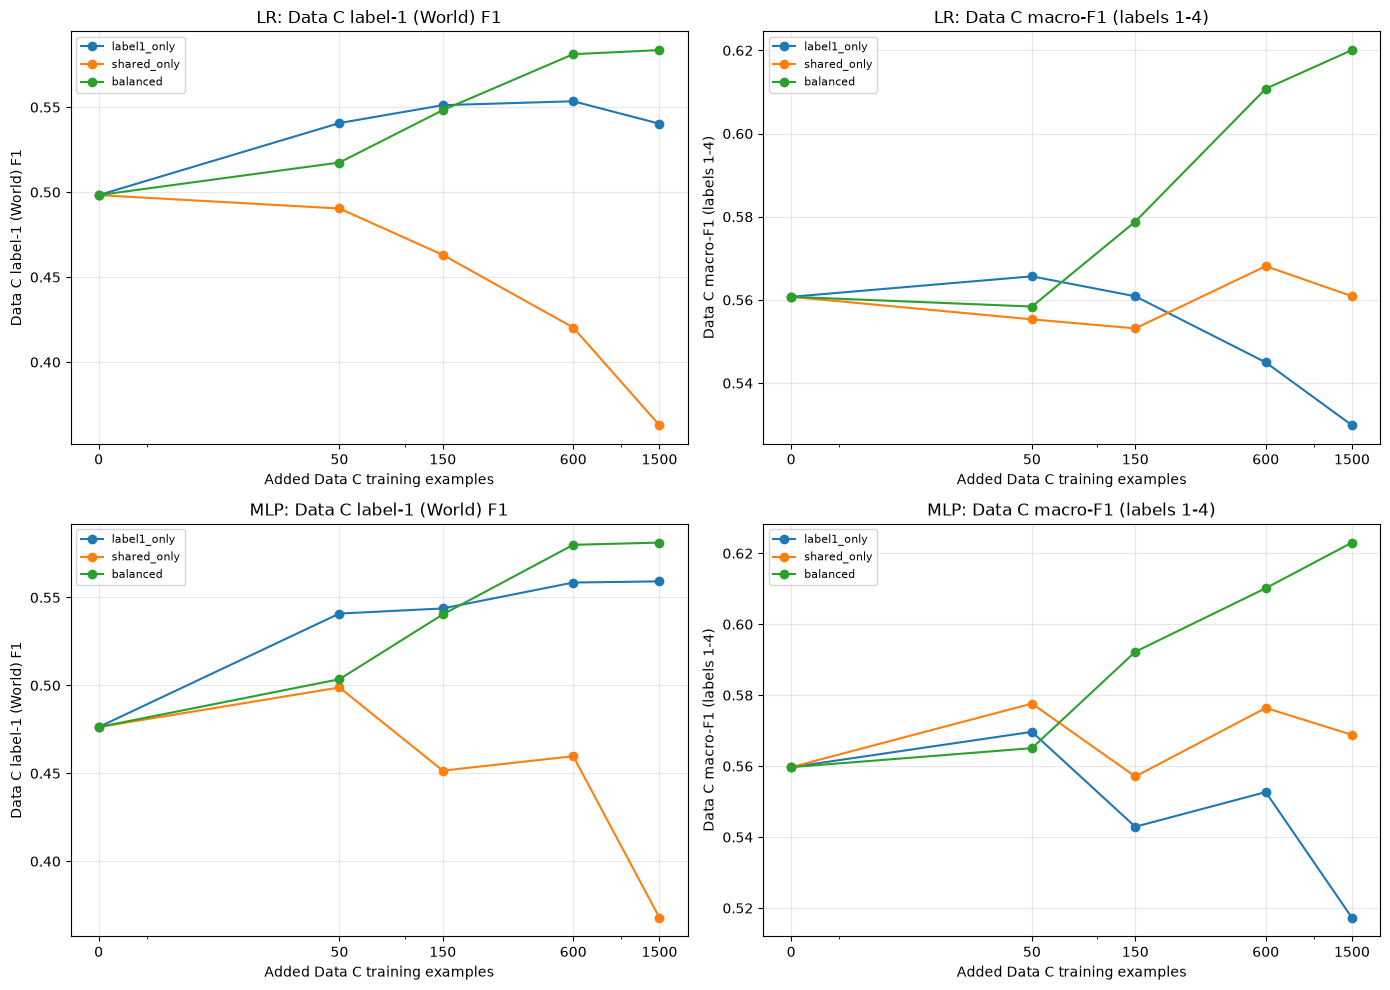

In [45]:
TICKS = [0] + BUDGETS
COLORS = {"label1_only": "tab:blue", "shared_only": "tab:orange", "balanced": "tab:green"}


def plot_strategy(ax, df, model, strategy, metric, **style):
    d = df[df.model == model]
    base = d.loc[d.budget == 0, metric].iloc[0]
    s = d[d.strategy == strategy].sort_values("budget")
    ax.plot([0] + s.budget.tolist(), [base] + s[metric].tolist(), marker="o", color=COLORS[strategy], **style)


def finish_axis(ax, ylabel, title):
    ax.set_xscale("symlog", linthresh=50)
    ax.set_xticks(TICKS)
    ax.set_xticklabels(TICKS)
    ax.set_xlabel("Added Data C training examples")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)


fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for i, model in enumerate(["LR", "MLP"]):
    for j, (metric, label) in enumerate([("C_label1_f1", "Data C label-1 (World) F1"),
                                         ("C_macro_f1", "Data C macro-F1 (labels 1-4)")]):
        for s in STRATEGIES:
            plot_strategy(axes[i, j], results_df, model, s, metric, label=s)
        finish_axis(axes[i, j], label, f"{model}: {label}")
plt.tight_layout()
plt.show()

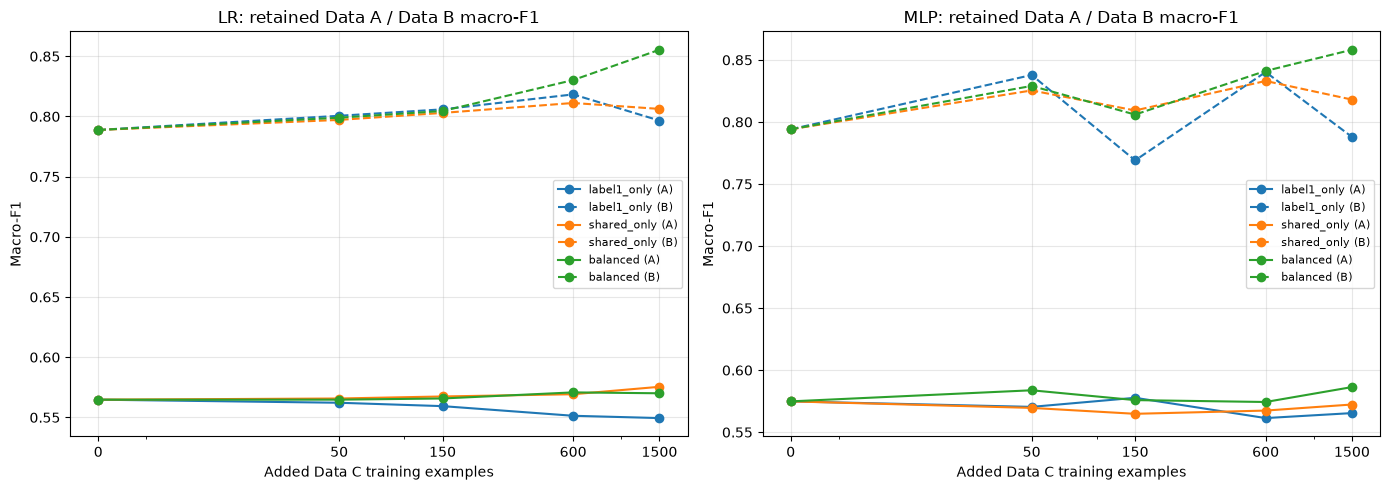

In [46]:
# do the Data A and Data B scores hold up?
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, model in zip(axes, ["LR", "MLP"]):
    for s in STRATEGIES:
        plot_strategy(ax, results_df, model, s, "A_macro_f1", label=f"{s} (A)")
        plot_strategy(ax, results_df, model, s, "B_macro_f1", linestyle="--", label=f"{s} (B)")
    finish_axis(ax, "Macro-F1", f"{model}: retained Data A / Data B macro-F1")
plt.tight_layout()
plt.show()

## Selected Component: Text-Representation Extension

We changed the features from unigram TF-IDF to unigram + bigram TF-IDF (`ngram_range=(1, 2)`, `min_df=2`). Each article gets its single words plus every pair of neighboring words. `min_df=2` drops terms that only show up in one training article, since most bigrams are rare.

This could help because phrases like "prime minister" or "stock market" say more about the topic than the separate words, which might make World easier to separate from Business and Technology. It could also hurt, since a lot of bigrams come from how one source writes and might not carry over to Data B or Data C. The bigger feature space also makes it easier for the MLP to overfit.

Everything else is the same as Parts 3 and 5, including the splits, seed, settings, selection rule, sampling, and metrics.

In [47]:
def make_ext_vectorizer():
    return TfidfVectorizer(ngram_range=(1, 2), min_df=2)


ext_split_vectorizer = make_ext_vectorizer()
Xe_tr = ext_split_vectorizer.fit_transform(article_text(p3_train))
Xe_val = ext_split_vectorizer.transform(article_text(p3_val))
print(f"Features: unigram {X_tr.shape[1]}, uni+bigram {Xe_tr.shape[1]}")

ext_sweep_df, ext_best, ext_epochs, _ = run_sweep(Xe_tr, Xe_val)
display(ext_sweep_df)
print(f"Selected LR: {ext_best['lr']} ({ext_epochs[ext_best['lr']]} epochs)")
print(f"Selected MLP: {ext_best['mlp']} ({ext_epochs[ext_best['mlp']]} epochs)")

Features: unigram 17857, uni+bigram 25465


,setting,model,best_epoch,val_accuracy,val_macro_f1
0,lr_wd0,LR,4,0.796667,0.796785
1,lr_wd1e-5,LR,11,0.804000,0.804305
2,lr_wd1e-4,LR,5,0.799333,0.800038
3,lr_wd1e-3,LR,6,0.771333,0.772498
4,mlp_none,MLP,2,0.808000,0.808541
5,mlp_dropout,MLP,8,0.812000,0.811734
6,mlp_dropout_wd,MLP,6,0.806000,0.806206
7,mlp_strong,MLP,5,0.758000,0.758731


Selected LR: lr_wd1e-5 (11 epochs)
Selected MLP: mlp_dropout (8 epochs)


,model,setting,representation,optimizer,learning_rate,weight_decay,dropout,batch_size,epochs,seed,train_size,vocab_size
0,LR,lr_wd1e-5,unigram + bigram TF-IDF (title + description),Adam,0.010,0.00001,none,64,11,0,7500,31068
1,MLP,mlp_dropout,unigram + bigram TF-IDF (title + description),Adam,0.001,0.00000,"(0.2, 0.3)",64,8,0,7500,31068


,model,setting,A_accuracy,A_macro_f1,B_accuracy,B_macro_f1,features
0,LR,lr_wd1e-5,0.5648,0.5647,0.7802,0.7888,unigram
1,MLP,mlp_dropout,0.5784,0.5749,0.7924,0.7941,unigram
0,LR,lr_wd1e-5,0.5672,0.5667,0.7146,0.7255,uni+bigram
1,MLP,mlp_dropout,0.5720,0.5715,0.7924,0.7988,uni+bigram


,model,class,A_precision_unigram,A_recall_unigram,A_f1_unigram,B_precision_unigram,B_recall_unigram,B_f1_unigram,A_precision_bigram,A_recall_bigram,A_f1_bigram,B_precision_bigram,B_recall_bigram,B_f1_bigram
0,LR,Politics,0.383,0.374,0.379,0.938,0.542,0.687,0.395,0.396,0.396,0.917,0.480,0.630
1,LR,Sports,0.652,0.664,0.658,0.982,0.871,0.923,0.645,0.670,0.658,0.976,0.787,0.871
2,LR,Business,0.612,0.564,0.587,0.527,0.990,0.688,0.582,0.554,0.568,0.459,0.990,0.627
3,LR,Technology,0.683,0.684,0.683,0.981,0.643,0.777,0.676,0.688,0.682,0.976,0.509,0.669
4,LR,Entertainment,0.497,0.538,0.517,0.977,0.782,0.869,0.533,0.528,0.531,0.976,0.723,0.830
5,MLP,Politics,0.404,0.372,0.388,0.874,0.468,0.609,0.388,0.384,0.386,0.934,0.542,0.686
6,MLP,Sports,0.667,0.696,0.681,0.983,0.896,0.938,0.673,0.686,0.679,0.978,0.885,0.929
7,MLP,Business,0.612,0.552,0.580,0.556,0.986,0.711,0.577,0.548,0.562,0.546,0.984,0.703
8,MLP,Technology,0.662,0.748,0.702,0.931,0.746,0.828,0.673,0.680,0.677,0.968,0.668,0.791
9,MLP,Entertainment,0.522,0.524,0.523,0.990,0.798,0.884,0.546,0.562,0.554,0.969,0.816,0.886


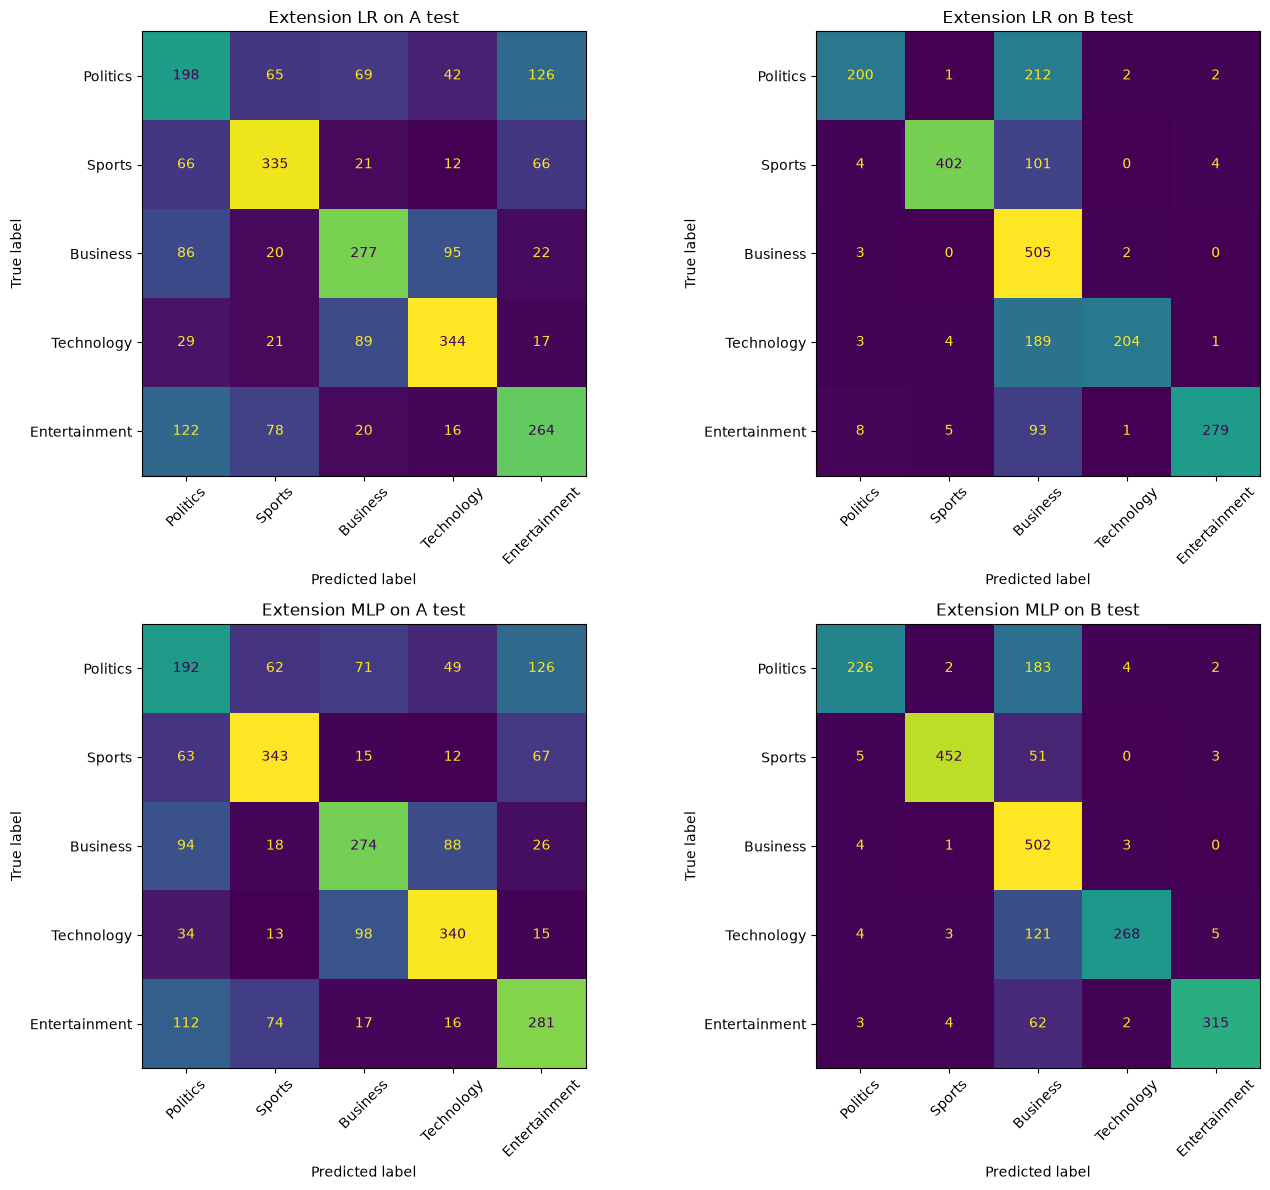

In [48]:
ext_vec, EXT_MODELS, ext_results = refit_and_test(make_ext_vectorizer, ext_best, ext_epochs)
display(config_table(ext_best, ext_epochs, "unigram + bigram TF-IDF (title + description)", ext_vec))

display(pd.concat([summary_table(final_results, best).assign(features="unigram"),
                   summary_table(ext_results, ext_best).assign(features="uni+bigram")]).round(4))

display(per_class_table(final_results).merge(per_class_table(ext_results), on=["model", "class"],
                                             suffixes=("_unigram", "_bigram")).round(3))

plot_confusion(ext_results, "Extension ")

In [49]:
# extension confusion matrix minus the unigram one
# positive off-diagonal numbers mean the extension makes that mistake more often
names = list(LABELS["Set A"])
for tag in ["lr", "mlp"]:
    for ds in ["A_test", "B_test"]:
        diff = ext_results[tag][ds]["confusion_matrix"] - final_results[tag][ds]["confusion_matrix"]
        print(f"{tag.upper()} {ds.replace('_', ' ')}")
        display(pd.DataFrame(diff, index=names, columns=names))

LR A test


,Politics,Sports,Business,Technology,Entertainment
Politics,11,5,-2,-1,-13
Sports,5,3,7,3,-18
Business,-2,4,-5,6,-3
Technology,-3,-2,10,2,-7
Entertainment,2,0,5,-2,-5


LR B test


,Politics,Sports,Business,Technology,Entertainment
Politics,-26,0,26,0,0
Sports,2,-43,40,0,1
Business,0,0,0,0,0
Technology,0,1,54,-54,-1
Entertainment,1,1,21,0,-23


MLP A test


,Politics,Sports,Business,Technology,Entertainment
Politics,6,2,-1,3,-10
Sports,10,-5,0,1,-6
Business,16,-2,-2,-23,11
Technology,10,-2,27,-34,-1
Entertainment,-7,-5,0,-7,19


MLP B test


,Politics,Sports,Business,Technology,Entertainment
Politics,31,1,-35,2,1
Sports,2,-6,3,0,1
Business,1,1,-1,-1,0
Technology,2,-1,25,-31,5
Entertainment,-17,1,23,-14,7


In [50]:
EXT_FINAL = {tag: (*ALL_SETTINGS[name], ext_epochs[name]) for tag, name in ext_best.items()}
ext_results_df = run_part5(EXT_FINAL, EXT_MODELS, ext_vec, make_ext_vectorizer)

key = ["model", "strategy", "budget"]
metrics = ["C_label1_recall", "C_label1_f1", "C_macro_f1", "C_strict_macro_f1_2to4", "A_macro_f1", "B_macro_f1"]
compare = results_df.merge(ext_results_df, on=key, suffixes=("_unigram", "_bigram"))
display(compare[key + [f"{m}_{v}" for m in metrics for v in ["unigram", "bigram"]]].round(4))

LR label1_only 50: C macro-F1 = 0.5553
LR label1_only 150: C macro-F1 = 0.5508
LR label1_only 600: C macro-F1 = 0.5374
LR label1_only 1500: C macro-F1 = 0.5156
LR shared_only 50: C macro-F1 = 0.5415
LR shared_only 150: C macro-F1 = 0.5430
LR shared_only 600: C macro-F1 = 0.5498
LR shared_only 1500: C macro-F1 = 0.5538
LR balanced 50: C macro-F1 = 0.5512
LR balanced 150: C macro-F1 = 0.5673
LR balanced 600: C macro-F1 = 0.5985
LR balanced 1500: C macro-F1 = 0.6082
MLP label1_only 50: C macro-F1 = 0.5507
MLP label1_only 150: C macro-F1 = 0.5484
MLP label1_only 600: C macro-F1 = 0.5150
MLP label1_only 1500: C macro-F1 = 0.5239
MLP shared_only 50: C macro-F1 = 0.5474
MLP shared_only 150: C macro-F1 = 0.5360
MLP shared_only 600: C macro-F1 = 0.5685
MLP shared_only 1500: C macro-F1 = 0.5742
MLP balanced 50: C macro-F1 = 0.5564
MLP balanced 150: C macro-F1 = 0.5618
MLP balanced 600: C macro-F1 = 0.6052
MLP balanced 1500: C macro-F1 = 0.6058


,model,strategy,budget,C_label1_recall_unigram,C_label1_recall_bigram,C_label1_f1_unigram,C_label1_f1_bigram,C_macro_f1_unigram,C_macro_f1_bigram,C_strict_macro_f1_2to4_unigram,C_strict_macro_f1_2to4_bigram,A_macro_f1_unigram,A_macro_f1_bigram,B_macro_f1_unigram,B_macro_f1_bigram
0,LR,baseline,0,0.430,0.406,0.4983,0.4822,0.5608,0.5484,0.5816,0.5705,0.5647,0.5667,0.7888,0.7255
1,LR,label1_only,50,0.552,0.536,0.5406,0.5265,0.5657,0.5553,0.5740,0.5649,0.5622,0.5687,0.8006,0.7257
2,LR,label1_only,150,0.630,0.614,0.5512,0.5381,0.5609,0.5508,0.5641,0.5551,0.5594,0.5634,0.8059,0.7525
3,LR,label1_only,600,0.714,0.720,0.5535,0.5538,0.5450,0.5374,0.5422,0.5319,0.5514,0.5623,0.8183,0.7470
4,LR,label1_only,1500,0.758,0.768,0.5403,0.5371,0.5299,0.5156,0.5264,0.5085,0.5494,0.5596,0.7966,0.7269
5,LR,shared_only,50,0.408,0.362,0.4904,0.4525,0.5553,0.5415,0.5770,0.5712,0.5657,0.5679,0.7971,0.7255
6,LR,shared_only,150,0.370,0.332,0.4631,0.4267,0.5532,0.5430,0.5832,0.5818,0.5674,0.5694,0.8029,0.7537
7,LR,shared_only,600,0.306,0.268,0.4203,0.3785,0.5681,0.5498,0.6174,0.6068,0.5693,0.5725,0.8112,0.7717
8,LR,shared_only,1500,0.246,0.236,0.3628,0.3501,0.5609,0.5538,0.6269,0.6217,0.5754,0.5732,0.8063,0.7773
9,LR,balanced,50,0.460,0.428,0.5174,0.4942,0.5584,0.5512,0.5721,0.5701,0.5647,0.5685,0.7990,0.7297


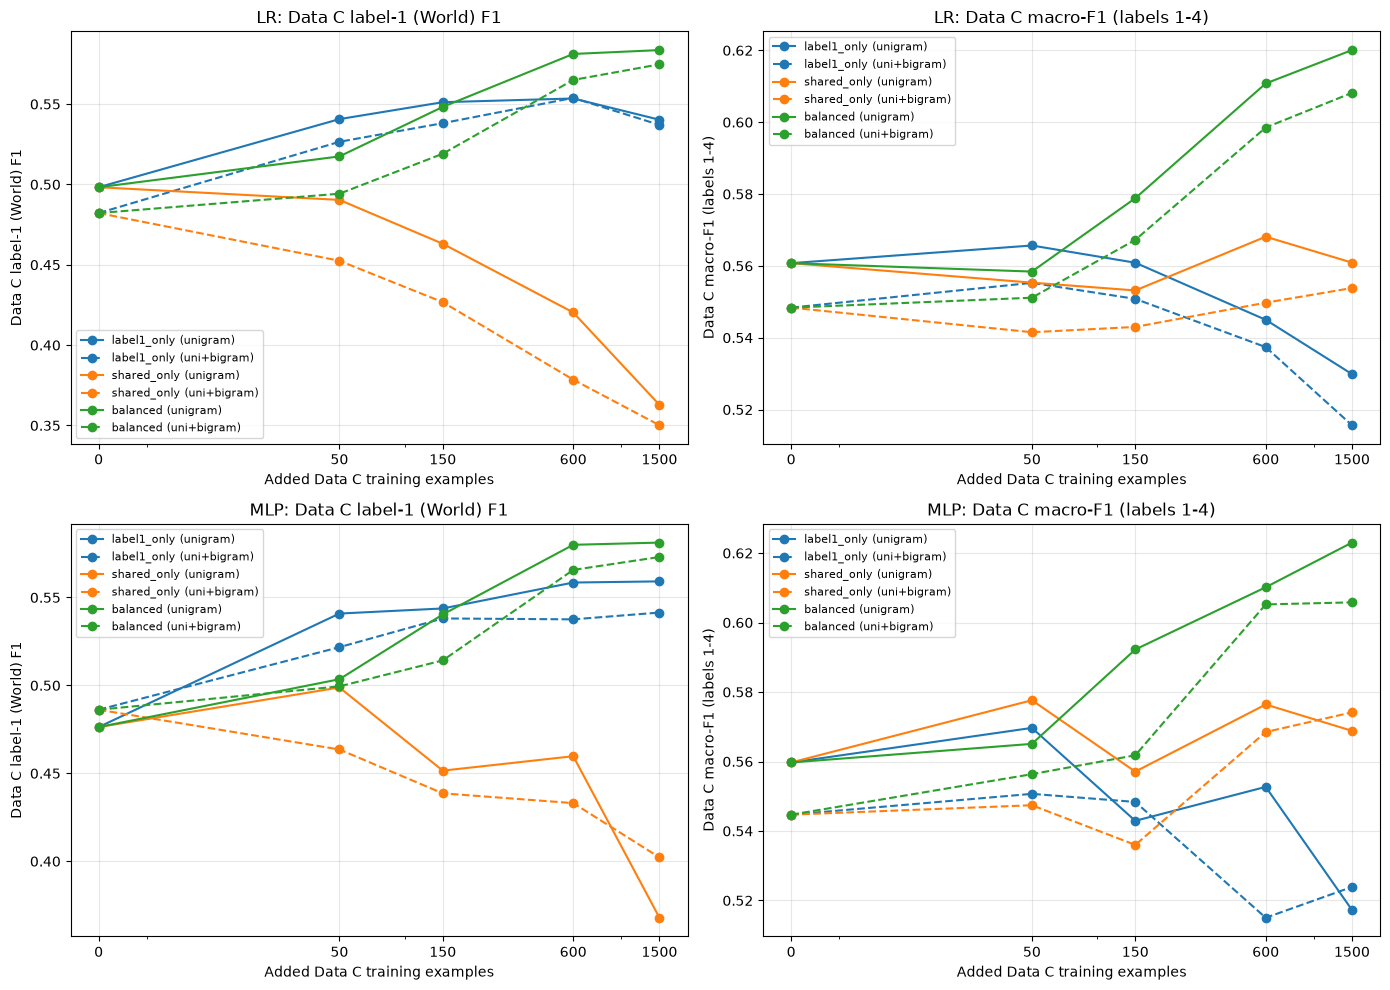

In [51]:
# solid lines are unigram, dashed lines are uni+bigram
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for i, model in enumerate(["LR", "MLP"]):
    for j, (metric, label) in enumerate([("C_label1_f1", "Data C label-1 (World) F1"),
                                         ("C_macro_f1", "Data C macro-F1 (labels 1-4)")]):
        for s in STRATEGIES:
            plot_strategy(axes[i, j], results_df, model, s, metric, label=f"{s} (unigram)")
            plot_strategy(axes[i, j], ext_results_df, model, s, metric, linestyle="--", label=f"{s} (uni+bigram)")
        finish_axis(axes[i, j], label, f"{model}: {label}")
plt.tight_layout()
plt.show()